# Monitorización inteligente del consumo energético residencial

## 1. Introducción

### 1.1. Contexto

El consumo energético residencial está relacionado con diferentes factores, entre ellos las condiciones ambientales, las características de las viviendas y los hábitos de sus ocupantes.

El análisis de datos procedentes de sistemas de monitorización permite estudiar estos comportamientos e identificar patrones de consumo.

### 1.2. Objetivo general

Analizar el comportamiento del consumo energético residencial y su relación con las condiciones ambientales interiores, identificando diferencias entre viviendas y entre las zonas urbanas UHI (Urban Heat Island) y UP (Urban Periphery).

### 1.3. Pregunta de investigación

¿Cómo se relacionan las condiciones ambientales interiores con el consumo energético de las viviendas, y qué diferencias existen entre hogares y entre zonas urbanas UHI y UP?

### 1.4. Fuente de datos principal

El proyecto parte del conjunto de datos MODIF-HABIT, que contiene información de monitorización de 20 viviendas situadas en Madrid.

Se dispone de las siguientes variables principales:

- Temperatura interior.
- Humedad relativa interior.
- Consumo eléctrico.
- Consumo de gas.

La frecuencia de registro declarada es de 15 minutos.

**Fuente:** https://doi.org/10.5281/zenodo.20367908

### 1.5. Enfoque metodológico

El proyecto seguirá ocho fases:

1. Selección de la temática y planteamiento del problema.
2. Obtención y validación de datos.
3. Formulación de hipótesis y estrategia analítica.
4. Preprocesamiento e integración.
5. Limpieza y control de calidad.
6. Análisis exploratorio de datos (EDA).
7. Verificación de hipótesis y conclusiones.
8. Documentación y presentación.

## 2. Obtención y validación de datos

### 2.1. Inventario de los archivos originales

El dataset MODIF-HABIT se distribuye en dos archivos comprimidos, correspondientes a dos grupos de viviendas de Madrid:

- **UHI:** viviendas situadas en zonas de isla de calor urbana.
- **UP:** viviendas situadas en zonas periféricas urbanas.

Antes de cargar los datos, se realizará un inventario de los archivos contenidos en ambos ZIP.

El objetivo de esta inspección es comprobar la estructura del dataset, identificar los archivos CSV disponibles y detectar posibles diferencias entre los grupos.

Los archivos originales se conservarán sin modificaciones en `src/data/raw/`.

In [1]:
from pathlib import Path
from zipfile import ZipFile

# Carpeta donde están los archivos originales
ruta_raw = Path("data/raw")

# Archivos ZIP que vamos a inspeccionar
archivos_zip = [
    "MADRID UHI.zip",
    "MADRID UP.zip"
]

for nombre_zip in archivos_zip:
    ruta_zip = ruta_raw / nombre_zip

    with ZipFile(ruta_zip) as zip_file:
        archivos = zip_file.namelist()

        # Excluimos las entradas que son carpetas
        archivos_reales = [
            archivo for archivo in archivos
            if not archivo.endswith("/")
        ]

        # Identificamos los CSV
        archivos_csv = [
            archivo for archivo in archivos_reales
            if archivo.lower().endswith(".csv")
        ]

        print(f"\nARCHIVO: {nombre_zip}")
        print(f"Total de archivos: {len(archivos_reales)}")
        print(f"Archivos CSV: {len(archivos_csv)}")
        print(f"Otros archivos: {len(archivos_reales) - len(archivos_csv)}")
        print("\nPrimeros 5 CSV:")

        for archivo in archivos_csv[:5]:
            print(" -", archivo)


ARCHIVO: MADRID UHI.zip
Total de archivos: 59
Archivos CSV: 59
Otros archivos: 0

Primeros 5 CSV:
 - MADRID UHI/D01/D01_HUMIDITY_21-05-2019_31-12-2019.csv
 - MADRID UHI/D01/D01_HUMIDITY_31-12-2019_12-11-2020.csv
 - MADRID UHI/D01/D01_Quarter Hourly Electrical Energy_21-05-2019_12-11-2020.csv
 - MADRID UHI/D01/D01_Quarter Hourly Gas Energy_21-05-2019_12-11-2020.csv
 - MADRID UHI/D01/D01_TEMPERATURE_21-05-2019_31-12-2019.csv

ARCHIVO: MADRID UP.zip
Total de archivos: 60
Archivos CSV: 60
Otros archivos: 0

Primeros 5 CSV:
 - MADRID UP/D05/D05_HUMIDITY_01-06-2019_31-12-2019.csv
 - MADRID UP/D05/D05_HUMIDITY_31-12-2019_30-06-2020.csv
 - MADRID UP/D05/D05_Quarter Hourly Electrical Energy_01-06-2019_08-02-2021.csv
 - MADRID UP/D05/D05_Quarter Hourly Gas Energy_01-06-2019_08-02-2021.csv
 - MADRID UP/D05/D05_TEMPERATURE_01-06-2019_31-12-2019.csv


### 2.2. Distribución de archivos por vivienda

En esta etapa se analiza cómo se distribuyen los archivos CSV entre las viviendas de los dos grupos.

La documentación del dataset describe seis archivos por vivienda: dos correspondientes a temperatura, dos a humedad relativa, uno a consumo eléctrico y uno a consumo de gas.

Se comprobará si esta estructura se cumple en los archivos originales y si existen diferencias entre viviendas.

Esta inspección permitirá detectar posibles ausencias antes de estudiar el contenido de los registros.

In [2]:
import pandas as pd
from pathlib import PurePosixPath

registros = []

for nombre_zip in archivos_zip:
    ruta_zip = ruta_raw / nombre_zip

    with ZipFile(ruta_zip) as zip_file:
        for archivo in zip_file.namelist():

            if not archivo.lower().endswith(".csv"):
                continue

            ruta_interna = PurePosixPath(archivo)

            vivienda = ruta_interna.parent.name
            nombre_archivo = ruta_interna.name.lower()

            if "humidity" in nombre_archivo:
                variable = "Humedad"
            elif "temperature" in nombre_archivo:
                variable = "Temperatura"
            elif "electrical energy" in nombre_archivo:
                variable = "Electricidad"
            elif "gas energy" in nombre_archivo:
                variable = "Gas"
            else:
                variable = "Sin clasificar"

            grupo = "UHI" if "UHI" in nombre_zip else "UP"

            registros.append({
                "grupo": grupo,
                "vivienda": vivienda,
                "variable": variable,
                "archivo": ruta_interna.name
            })

# Creamos una tabla de distribución
df_inventario = pd.DataFrame(registros)

tabla_inventario = pd.crosstab(
    [df_inventario["grupo"], df_inventario["vivienda"]],
    df_inventario["variable"]
)

display(tabla_inventario)

variable        Electricidad  Gas  Humedad  Temperatura
grupo vivienda                                         
UHI   D01                  1    1        2            2
      D02                  1    1        2            2
      D03                  1    1        2            2
      D04                  1    1        2            2
      D06                  1    1        2            2
      D09                  1    1        2            2
      D11                  0    1        2            2
      D13                  1    1        2            2
      D15                  1    1        2            2
      D16                  1    1        2            2
UP    D05                  1    1        2            2
      D07                  1    1        2            2
      D08                  1    1        2            2
      D10                  1    1        2            2
      D12                  1    1        2            2
      D14                  1    1        2            2
      D17                  1    1        2            2
      D18                  1    1        2            2
      D19                  1    1        2            2
      D20                  1    1        2            2

### 2.3. Resultados del inventario por vivienda

El inventario identifica 20 viviendas distribuidas en dos grupos: 10 UHI y 10 UP.

La distribución de archivos coincide con la estructura de seis CSV por vivienda descrita en la documentación, con una excepción:

- La vivienda D11, perteneciente al grupo UHI, no presenta ningún archivo identificado como consumo eléctrico.

La distribución resultante es de 59 archivos CSV para UHI y 60 para UP, frente a los 60 esperados para cada grupo si todas las viviendas dispusieran de los seis archivos.

Esta diferencia explica el desequilibrio detectado en el inventario inicial.

**Incidencia pendiente de investigación:** se comprobará si el archivo de electricidad de D11 está realmente ausente y si existe alguna explicación en la documentación del dataset.

No se excluirá la vivienda D11 del estudio por esta circunstancia. Su posible utilización dependerá de la disponibilidad de datos para cada análisis.

In [3]:
# Inspeccionamos todos los archivos de la vivienda D11

for nombre_zip in archivos_zip:

    if "UHI" not in nombre_zip:
        continue

    ruta_zip = ruta_raw / nombre_zip

    with ZipFile(ruta_zip) as zip_file:

        archivos_d11 = [
            archivo
            for archivo in zip_file.namelist()
            if "/D11/" in archivo
        ]

        print("ARCHIVOS DE LA VIVIENDA D11:")

        for archivo in archivos_d11:
            print("-", archivo)

ARCHIVOS DE LA VIVIENDA D11:
- MADRID UHI/D11/
- MADRID UHI/D11/D11_HUMIDITY_01-06-2019_31-12-2019.csv
- MADRID UHI/D11/D11_HUMIDITY_31-12-2019_30-06-2020.csv
- MADRID UHI/D11/D11_Quarter Hourly Gas Energy_01-06-2019_31-05-2020.csv
- MADRID UHI/D11/D11_TEMPERATURE_01-06-2019_31-12-2019.csv
- MADRID UHI/D11/D11_TEMPERATURE_31-12-2019_30-06-2020.csv


### 2.4. Incidencia identificada en la vivienda D11

La inspección individual de los archivos de D11 confirma que contiene cinco archivos CSV:

- Dos archivos de humedad relativa.
- Dos archivos de temperatura.
- Un archivo de consumo de gas.

No se ha encontrado ningún archivo de consumo eléctrico.

Por tanto, se confirma la ausencia de esta variable en los archivos originales disponibles para D11.

**Decisión provisional:** mantener D11 en el conjunto de datos y utilizarla únicamente en los análisis para los que disponga de información suficiente. No se imputará ni se inventará el consumo eléctrico ausente.

In [4]:
# Seleccionar un archivo representativo de cada variable

archivos_muestra = {}

with ZipFile(ruta_raw / "MADRID UHI.zip") as zip_file:

    for archivo in zip_file.namelist():

        nombre = archivo.lower()

        if not nombre.endswith(".csv"):
            continue

        if "d01/" not in nombre:
            continue

        if "temperature" in nombre:
            archivos_muestra["Temperatura"] = archivo

        elif "humidity" in nombre:
            archivos_muestra["Humedad"] = archivo

        elif "electrical energy" in nombre:
            archivos_muestra["Electricidad"] = archivo

        elif "gas energy" in nombre:
            archivos_muestra["Gas"] = archivo

    for variable, archivo in archivos_muestra.items():

        with zip_file.open(archivo) as fichero:
            df = pd.read_csv(fichero)

        print(f"\n--- {variable} ---")
        print("Archivo:", archivo)
        print("Dimensiones:", df.shape)
        print("Columnas:", df.columns.tolist())
        display(df.head(3))


--- Humedad ---
Archivo: MADRID UHI/D01/D01_HUMIDITY_31-12-2019_12-11-2020.csv
Dimensiones: (22894, 4)
Columnas: ['Unnamed: 0', 'Unnamed: 1', 'From', '31/12/2019']


,Unnamed: 0,Unnamed: 1,From,31/12/2019
0,NaN,NaN,To,12/11/2020
1,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN



--- Electricidad ---
Archivo: MADRID UHI/D01/D01_Quarter Hourly Electrical Energy_21-05-2019_12-11-2020.csv
Dimensiones: (35561, 4)
Columnas: ['Unnamed: 0', 'Unnamed: 1', 'From', '21/05/2019']


,Unnamed: 0,Unnamed: 1,From,21/05/2019
0,NaN,NaN,To,12/11/2020
1,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN



--- Gas ---
Archivo: MADRID UHI/D01/D01_Quarter Hourly Gas Energy_21-05-2019_12-11-2020.csv
Dimensiones: (23992, 4)
Columnas: ['Unnamed: 0', 'Unnamed: 1', 'From', '21/05/2019']


,Unnamed: 0,Unnamed: 1,From,21/05/2019
0,NaN,NaN,To,12/11/2020
1,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN



--- Temperatura ---
Archivo: MADRID UHI/D01/D01_TEMPERATURE_31-12-2019_12-11-2020.csv
Dimensiones: (22894, 4)
Columnas: ['Unnamed: 0', 'Unnamed: 1', 'From', '31/12/2019']


,Unnamed: 0,Unnamed: 1,From,31/12/2019
0,NaN,NaN,To,12/11/2020
1,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN


In [5]:
# Inspeccionar las primeras 15 filas de cada archivo

with ZipFile(ruta_raw / "MADRID UHI.zip") as zip_file:

    for variable, archivo in archivos_muestra.items():

        with zip_file.open(archivo) as fichero:
            df = pd.read_csv(
                fichero,
                header=None
            )

        print(f"\n{'='*60}")
        print(f"VARIABLE: {variable}")
        print(f"ARCHIVO: {archivo}")
        print(f"{'='*60}")

        display(df.head(15))


VARIABLE: Humedad
ARCHIVO: MADRID UHI/D01/D01_HUMIDITY_31-12-2019_12-11-2020.csv


,0,1,2,3
0,NaN,NaN,From,31/12/2019
1,NaN,NaN,To,12/11/2020
2,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN
4,NaN,NaN,Display-Humedad[%],NaN
5,NaN,AVERAGE,41.91,NaN
6,NaN,MEDIAN,42,NaN
7,NaN,MAX,55,NaN
8,NaN,MIN,23.07,NaN
9,NaN,NaN,NaN,NaN



VARIABLE: Electricidad
ARCHIVO: MADRID UHI/D01/D01_Quarter Hourly Electrical Energy_21-05-2019_12-11-2020.csv


,0,1,2,3
0,NaN,NaN,From,21/05/2019
1,NaN,NaN,To,12/11/2020
2,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN
6,NaN,NaN,Electricidad [kWh],NaN
7,NaN,TOTAL,"3,524.31",NaN
8,NaN,AVERAGE,0.1,NaN
9,NaN,MEDIAN,0.05,NaN



VARIABLE: Gas
ARCHIVO: MADRID UHI/D01/D01_Quarter Hourly Gas Energy_21-05-2019_12-11-2020.csv


,0,1,2,3
0,NaN,NaN,From,21/05/2019
1,NaN,NaN,To,12/11/2020
2,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN
6,NaN,NaN,Gas [kWh],NaN
7,NaN,TOTAL,"3,846.07",NaN
8,NaN,AVERAGE,0.16,NaN
9,NaN,MEDIAN,0.02,NaN



VARIABLE: Temperatura
ARCHIVO: MADRID UHI/D01/D01_TEMPERATURE_31-12-2019_12-11-2020.csv


,0,1,2,3
0,NaN,NaN,From,31/12/2019
1,NaN,NaN,To,12/11/2020
2,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN
4,NaN,NaN,Display-Temperature[℃],NaN
5,NaN,AVERAGE,24.36,NaN
6,NaN,MEDIAN,23.39,NaN
7,NaN,MAX,30.38,NaN
8,NaN,MIN,19.1,NaN
9,NaN,NaN,NaN,NaN


### 2.5. Estructura interna de los archivos CSV

La inspección de archivos representativos de D01 permite identificar dos bloques diferenciados.

**Bloque de metadatos:**
- Periodo de inicio y finalización.
- Nombre de la variable y unidad de medida.
- Estadísticas descriptivas agregadas.

**Bloque de mediciones:**
- Fecha.
- Hora.
- Valor registrado.

Los archivos ambientales (temperatura y humedad) presentan el encabezado de mediciones en el índice 12, mientras que los archivos energéticos (electricidad y gas) lo presentan en el índice 14.

Se observa también una diferencia en el nombre de la columna temporal: `Time` para las variables ambientales y `Hour` para las energéticas.

Las unidades identificadas son:

| Variable | Unidad |
|---|---|
| Temperatura | °C |
| Humedad relativa | % |
| Electricidad | kWh |
| Gas | kWh |

La cuarta columna de los archivos inspeccionados aparece vacía en las primeras filas mostradas.

**Decisión metodológica:** antes de integrar los datos será necesario identificar correctamente las filas de encabezado y separar los metadatos de los registros de medición. Se conservarán los archivos originales sin modificaciones.

In [6]:
# Inspeccionar las últimas filas de los archivos representativos

with ZipFile(ruta_raw / "MADRID UHI.zip") as zip_file:

    for variable, archivo in archivos_muestra.items():

        with zip_file.open(archivo) as fichero:
            df = pd.read_csv(fichero, header=None)

        print(f"\n--- {variable} ---")
        display(df.tail(5))


--- Humedad ---


,0,1,2,3
22890,6/9/2020,7:30,35.45,NaN
22891,6/9/2020,7:45,36,NaN
22892,6/9/2020,8:00,36,NaN
22893,6/9/2020,8:15,36,NaN
22894,6/9/2020,8:30,36.12,NaN



--- Electricidad ---


,0,1,2,3
35557,6/9/2020,7:15,0.05,NaN
35558,6/9/2020,7:30,0.03,NaN
35559,6/9/2020,7:45,0.1,NaN
35560,6/9/2020,8:00,0.03,NaN
35561,6/9/2020,8:15,0.04,NaN



--- Gas ---


,0,1,2,3
23988,6/9/2020,7:15,0,NaN
23989,6/9/2020,7:30,0,NaN
23990,6/9/2020,7:45,0,NaN
23991,6/9/2020,8:00,0,NaN
23992,6/9/2020,8:15,0.18,NaN



--- Temperatura ---


,0,1,2,3
22890,6/9/2020,7:30,27.24,NaN
22891,6/9/2020,7:45,27.2,NaN
22892,6/9/2020,8:00,27.2,NaN
22893,6/9/2020,8:15,27.2,NaN
22894,6/9/2020,8:30,27.13,NaN


In [7]:
# Comprobar el periodo real de los registros

with ZipFile(ruta_raw / "MADRID UHI.zip") as zip_file:

    for variable, archivo in archivos_muestra.items():

        # Identificar la fila del encabezado
        fila_cabecera = 12 if variable in ["Humedad", "Temperatura"] else 14

        with zip_file.open(archivo) as fichero:
            df = pd.read_csv(fichero, header=None)

        # Extraer únicamente las mediciones
        datos = df.iloc[fila_cabecera + 1:, :3].copy()

        datos.columns = ["fecha", "hora", "valor"]

        # Convertir la fecha
        datos["fecha"] = pd.to_datetime(
            datos["fecha"],
            dayfirst=True,
            errors="coerce"
        )

        print(f"\n--- {variable} ---")
        print("Registros:", len(datos))
        print("Primer registro:", datos["fecha"].min())
        print("Último registro:", datos["fecha"].max())
        print("Valores ausentes:", datos["valor"].isna().sum())


--- Humedad ---
Registros: 22882
Primer registro: 2019-12-31 00:00:00
Último registro: 2020-09-06 00:00:00
Valores ausentes: 0

--- Electricidad ---
Registros: 35547
Primer registro: 2019-05-21 00:00:00
Último registro: 2020-09-06 00:00:00
Valores ausentes: 0

--- Gas ---
Registros: 23978
Primer registro: 2019-12-19 00:00:00
Último registro: 2020-09-06 00:00:00
Valores ausentes: 0

--- Temperatura ---
Registros: 22882
Primer registro: 2019-12-31 00:00:00
Último registro: 2020-09-06 00:00:00
Valores ausentes: 0


### 2.6. Comprobación preliminar de los periodos registrados

Se han inspeccionado los registros de los cuatro archivos correspondientes a D01.

Los resultados muestran que los cuatro archivos terminan el 6 de septiembre de 2020, aunque sus metadatos y nombres declaran periodos que llegan al 12 de noviembre de 2020.

También se observa una diferencia en las fechas iniciales: el archivo de gas contiene como primer día registrado el 19 de diciembre de 2019, mientras que su nombre declara el 21 de mayo de 2019.

En los cuatro archivos se han obtenido cero valores ausentes en la columna de mediciones.

**Incidencias pendientes:**
- Diferencia entre el periodo declarado y el periodo realmente registrado.
- Diferencia entre la fecha inicial declarada y la primera fecha de gas observada.
- Pendiente comprobar la continuidad temporal y la disponibilidad de fechas y horas.

In [8]:
# Comprobar continuidad temporal en los cuatro archivos

with ZipFile(ruta_raw / "MADRID UHI.zip") as zip_file:

    for variable, archivo in archivos_muestra.items():

        fila_cabecera = 12 if variable in ["Humedad", "Temperatura"] else 14

        with zip_file.open(archivo) as fichero:
            df = pd.read_csv(fichero, header=None)

        datos = df.iloc[fila_cabecera + 1:, :3].copy()
        datos.columns = ["fecha", "hora", "valor"]

        # Construir una fecha y hora completas
        datos["fecha_hora"] = pd.to_datetime(
            datos["fecha"].astype(str) + " " + datos["hora"].astype(str),
            dayfirst=True,
            errors="coerce"
        )

        # Calcular diferencias entre registros consecutivos
        diferencias = datos["fecha_hora"].diff()

        print(f"\n--- {variable} ---")
        print("Fechas inválidas:", datos["fecha_hora"].isna().sum())
        print("Primer registro:", datos["fecha_hora"].min())
        print("Último registro:", datos["fecha_hora"].max())
        print("Intervalo más frecuente:")
        print(diferencias.value_counts().head(5))


--- Humedad ---
Fechas inválidas: 0
Primer registro: 2019-12-31 00:00:00
Último registro: 2020-09-06 08:30:00
Intervalo más frecuente:
fecha_hora
0 days 00:15:00    22699
0 days 00:30:00       84
0 days 00:45:00       32
0 days 01:00:00       19
0 days 01:30:00        9
Name: count, dtype: int64

--- Electricidad ---
Fechas inválidas: 0
Primer registro: 2019-05-21 17:15:00
Último registro: 2020-09-06 08:15:00
Intervalo más frecuente:
fecha_hora
0 days 00:15:00    35510
0 days 00:30:00       23
0 days 00:45:00        4
0 days 01:15:00        2
0 days 01:00:00        1
Name: count, dtype: int64

--- Gas ---
Fechas inválidas: 0
Primer registro: 2019-12-19 17:30:00
Último registro: 2020-09-06 08:15:00
Intervalo más frecuente:
fecha_hora
0 days 00:15:00    23765
0 days 00:30:00      109
0 days 00:45:00       37
0 days 01:00:00       15
0 days 01:15:00       12
Name: count, dtype: int64

--- Temperatura ---
Fechas inválidas: 0
Primer registro: 2019-12-31 00:00:00
Último registro: 2020-09-06

### 2.7. Comprobación de la frecuencia temporal

Se ha comprobado la continuidad temporal de los registros de D01 mediante la diferencia entre marcas temporales consecutivas.

Los resultados muestran que el intervalo predominante es de 15 minutos en las cuatro variables.

Sin embargo, también aparecen intervalos superiores a 15 minutos, lo que indica interrupciones en la continuidad temporal.

Se observa que temperatura y humedad presentan distribuciones idénticas de intervalos, mientras que electricidad y gas presentan diferencias.

No se han detectado fechas u horas inválidas durante esta comprobación.

**Conclusión provisional:** los datos tienen una frecuencia nominal de 15 minutos, pero no presentan una continuidad temporal perfecta. Será necesario cuantificar las interrupciones antes de integrar las variables.

In [9]:
# Resumen de continuidad temporal de D01

with ZipFile(ruta_raw / "MADRID UHI.zip") as zip_file:

    for variable, archivo in archivos_muestra.items():

        fila_cabecera = 12 if variable in ["Humedad", "Temperatura"] else 14

        with zip_file.open(archivo) as fichero:
            df = pd.read_csv(fichero, header=None)

        datos = df.iloc[fila_cabecera + 1:, :3].copy()
        datos.columns = ["fecha", "hora", "valor"]

        datos["fecha_hora"] = pd.to_datetime(
            datos["fecha"].astype(str) + " " + datos["hora"].astype(str),
            dayfirst=True,
            errors="coerce"
        )

        diferencias = datos["fecha_hora"].diff()

        interrupciones = diferencias[diferencias > pd.Timedelta(minutes=15)]

        print(f"\n--- {variable} ---")
        print("Registros duplicados:",
              datos["fecha_hora"].duplicated().sum())
        print("Interrupciones:", len(interrupciones))
        print("Interrupción máxima:", interrupciones.max())


--- Humedad ---
Registros duplicados: 0
Interrupciones: 182
Interrupción máxima: 4 days 07:15:00

--- Electricidad ---
Registros duplicados: 0
Interrupciones: 36
Interrupción máxima: 97 days 22:15:00

--- Gas ---
Registros duplicados: 0
Interrupciones: 212
Interrupción máxima: 4 days 07:15:00

--- Temperatura ---
Registros duplicados: 0
Interrupciones: 182
Interrupción máxima: 4 days 07:15:00


### 2.8. Duplicados e interrupciones temporales en D01

Se ha comprobado la existencia de marcas temporales duplicadas y de interrupciones en los archivos de la vivienda D01, utilizada como muestra inicial para la inspección.

En los cuatro archivos seleccionados no se identifican marcas temporales duplicadas.

La inspección inicial por archivo muestra las siguientes interrupciones máximas:

| Variable | Interrupción máxima observada en el archivo inspeccionado |
|---|---|
| Humedad | 4 días, 7 h y 15 min |
| Electricidad | 97 días, 22 h y 15 min |
| Gas | 4 días, 7 h y 15 min |
| Temperatura | 4 días, 7 h y 15 min |

**Importante:** estos valores proceden de la comprobación inicial de archivos individuales. No representan necesariamente la continuidad de la serie completa de cada variable, porque algunas viviendas tienen varios archivos consecutivos para una misma variable. La continuidad consolidada de D01 se comprobará más adelante combinando todos sus archivos.

**Conclusión provisional:** la inspección inicial permite identificar incidencias temporales en D01, pero sus resultados no pueden extrapolarse al conjunto de las viviendas. La validación global y el análisis consolidado permitirán caracterizar mejor estas interrupciones.

No se eliminarán viviendas ni se imputarán valores durante esta fase.

### 2.9. Validación global de los archivos

Después de inspeccionar individualmente la vivienda D01, se amplía la comprobación al conjunto de los 119 archivos CSV correspondientes a las 20 viviendas.

El objetivo es evaluar la disponibilidad y continuidad temporal de las mediciones, identificando diferencias entre hogares y tipos de variables.

Se calcularán los siguientes indicadores:

- Número de registros con fecha y hora válidas.
- Número de fechas inválidas.
- Número de valores no numéricos.
- Primera y última fecha registrada.
- Mayor intervalo temporal entre registros consecutivos.

Esta comprobación permitirá conocer la calidad estructural y temporal del conjunto de datos antes de decidir cómo preparar e integrar las mediciones.

In [10]:
print(archivos_zip)
print(ruta_raw)
print(df_inventario.shape)

['MADRID UHI.zip', 'MADRID UP.zip']
data/raw
(119, 4)


In [11]:
def validar_archivo(zip_file, archivo):

    nombre = archivo.lower()

    # Identificar la fila del encabezado
    if "temperature" in nombre or "humidity" in nombre:
        fila_cabecera = 12
    else:
        fila_cabecera = 14

    # Leer el CSV original
    with zip_file.open(archivo) as fichero:
        df = pd.read_csv(fichero, header=None)

    # Extraer las columnas de medición
    datos = df.iloc[fila_cabecera + 1:, :3].copy()
    datos.columns = ["fecha", "hora", "valor"]

    # Construir fecha y hora
    datos["fecha_hora"] = pd.to_datetime(
        datos["fecha"].astype(str) + " " + datos["hora"].astype(str),
        dayfirst=True,
        errors="coerce"
    )

    # Separar registros con fecha válida
    datos_validos = datos[
        datos["fecha_hora"].notna()
    ].copy()

    # Identificar valores ausentes
    valores_originales = datos_validos["valor"]

    mascara_ausentes = (
        valores_originales.isna()
        | valores_originales.astype("string").str.strip().eq("").fillna(False)
    )

    # Convertir los valores a formato numérico
    valores_numericos = pd.to_numeric(
        valores_originales,
        errors="coerce"
    )

    # Identificar valores no numéricos, excluyendo los ausentes
    mascara_no_numericos = (
        ~mascara_ausentes
        & valores_numericos.isna()
    )

    # Calcular porcentajes
    total_registros = len(datos_validos)

    porcentaje_ausentes = (
        mascara_ausentes.sum() / total_registros * 100
        if total_registros > 0 else 0
    )

    porcentaje_no_numericos = (
        mascara_no_numericos.sum() / total_registros * 100
        if total_registros > 0 else 0
    )

    # Analizar continuidad temporal
    fechas = datos_validos["fecha_hora"].sort_values()
    diferencias = fechas.diff()

    intervalos_largos = diferencias[
        diferencias > pd.Timedelta(minutes=15)
    ]

    return {
        "registros_validos": total_registros,
        "fechas_invalidas": datos["fecha_hora"].isna().sum(),
        "valores_ausentes": mascara_ausentes.sum(),
        "porcentaje_ausentes": porcentaje_ausentes,
        "valores_no_numericos": mascara_no_numericos.sum(),
        "porcentaje_no_numericos": porcentaje_no_numericos,
        "primera_fecha": fechas.min(),
        "ultima_fecha": fechas.max(),
        "mayor_intervalo": intervalos_largos.max()
    }


In [12]:
resultados = []

for _, fila in df_inventario.iterrows():

    grupo = fila["grupo"]
    vivienda = fila["vivienda"]
    archivo = fila["archivo"]

    # Localizar el ZIP correspondiente
    ruta_zip = ruta_raw / f"MADRID {grupo}.zip"

    # Construir la ruta interna del CSV
    ruta_interna = f"MADRID {grupo}/{vivienda}/{archivo}"

    with ZipFile(ruta_zip) as zip_file:
        resultado = validar_archivo(zip_file, ruta_interna)

    resultado["grupo"] = grupo
    resultado["vivienda"] = vivienda
    resultado["variable"] = fila["variable"]
    resultado["archivo"] = archivo

    resultados.append(resultado)

df_validacion = pd.DataFrame(resultados)

display(df_validacion.head())

,registros_validos,fechas_invalidas,valores_ausentes,porcentaje_ausentes,valores_no_numericos,porcentaje_no_numericos,primera_fecha,ultima_fecha,mayor_intervalo,grupo,vivienda,variable,archivo
0,10805,0,0,0.0,0,0.0,2019-05-21 17:45:00,2019-12-31 00:00:00,97 days 22:15:00,UHI,D01,Humedad,D01_HUMIDITY_21-05-2019_31-12-2019.csv
1,22882,0,0,0.0,0,0.0,2019-12-31 00:00:00,2020-09-06 08:30:00,4 days 07:15:00,UHI,D01,Humedad,D01_HUMIDITY_31-12-2019_12-11-2020.csv
2,35547,0,0,0.0,0,0.0,2019-05-21 17:15:00,2020-09-06 08:15:00,97 days 22:15:00,UHI,D01,Electricidad,D01_Quarter Hourly Electrical Energy_21-05-201...
3,23978,0,0,0.0,0,0.0,2019-12-19 17:30:00,2020-09-06 08:15:00,4 days 07:15:00,UHI,D01,Gas,D01_Quarter Hourly Gas Energy_21-05-2019_12-11...
4,10805,0,0,0.0,0,0.0,2019-05-21 17:45:00,2019-12-31 00:00:00,97 days 22:15:00,UHI,D01,Temperatura,D01_TEMPERATURE_21-05-2019_31-12-2019.csv


In [13]:
print("TOTAL DE ARCHIVOS:", len(df_validacion))

print("\nFECHAS INVÁLIDAS:")
print(df_validacion["fechas_invalidas"].sum())

print("\nVALORES AUSENTES:")
print(df_validacion["valores_ausentes"].sum())

print("\nVALORES NO NUMÉRICOS:")
print(df_validacion["valores_no_numericos"].sum())

print("\nREGISTROS VÁLIDOS:")
print(df_validacion["registros_validos"].sum())

print("\nARCHIVOS POR GRUPO:")
display(df_validacion.groupby("grupo").size())

print("\nARCHIVOS CON MAYOR INTERVALO TEMPORAL:")
display(
    df_validacion.sort_values(
        "mayor_intervalo",
        ascending=False
    ).head(10)[
        ["grupo", "vivienda", "variable",
         "registros_validos", "mayor_intervalo"]
    ]
)

TOTAL DE ARCHIVOS: 119

FECHAS INVÁLIDAS:
0

VALORES AUSENTES:
0

VALORES NO NUMÉRICOS:
0

REGISTROS VÁLIDOS:
3479361

ARCHIVOS POR GRUPO:


grupo
UHI    59
UP     60
dtype: int64


ARCHIVOS CON MAYOR INTERVALO TEMPORAL:


,grupo,vivienda,variable,registros_validos,mayor_intervalo
0,UHI,D01,Humedad,10805,97 days 22:15:00
2,UHI,D01,Electricidad,35547,97 days 22:15:00
4,UHI,D01,Temperatura,10805,97 days 22:15:00
103,UP,D18,Electricidad,53539,60 days 15:15:00
104,UP,D18,Gas,44713,60 days 15:15:00
44,UHI,D13,Gas,52916,35 days 19:15:00
43,UHI,D13,Electricidad,55920,35 days 19:15:00
9,UHI,D02,Gas,40705,28 days 01:30:00
12,UHI,D03,Electricidad,48816,27 days 04:45:00
7,UHI,D02,Humedad,25571,24 days 07:00:00


In [14]:
display(
    df_validacion.groupby(
        ["grupo", "variable"]
    ).agg(
        archivos=("archivo", "count"),
        registros=("registros_validos", "sum"),
        inicio=("primera_fecha", "min"),
        fin=("ultima_fecha", "max")
    ).reset_index()
)

,grupo,variable,archivos,registros,inicio,fin
0,UHI,Electricidad,9,454940,2019-05-16 11:30:00,2021-02-08 18:00:00
1,UHI,Gas,10,457755,2019-05-16 11:30:00,2021-02-08 18:00:00
2,UHI,Humedad,20,361425,2019-05-16 11:45:00,2020-11-12 00:00:00
3,UHI,Temperatura,20,361425,2019-05-16 11:45:00,2020-11-12 00:00:00
4,UP,Electricidad,10,583498,2019-06-01 00:00:00,2021-02-08 18:30:00
5,UP,Gas,10,508090,2019-06-01 00:00:00,2021-02-08 18:30:00
6,UP,Humedad,20,376114,2019-06-01 00:00:00,2020-06-30 00:00:00
7,UP,Temperatura,20,376114,2019-06-01 00:00:00,2020-06-30 00:00:00


In [15]:
cobertura_viviendas = (
    df_validacion
    .groupby(["grupo", "vivienda", "variable"])
    .agg(
        registros=("registros_validos", "sum"),
        inicio=("primera_fecha", "min"),
        fin=("ultima_fecha", "max"),
        mayor_intervalo=("mayor_intervalo", "max")
    )
    .reset_index()
)

display(
    cobertura_viviendas.sort_values(
        ["grupo", "vivienda", "variable"]
    )
)

,grupo,vivienda,variable,registros,inicio,fin,mayor_intervalo
0,UHI,D01,Electricidad,35547,2019-05-21 17:15:00,2020-09-06 08:15:00,97 days 22:15:00
1,UHI,D01,Gas,23978,2019-12-19 17:30:00,2020-09-06 08:15:00,4 days 07:15:00
2,UHI,D01,Humedad,33687,2019-05-21 17:45:00,2020-09-06 08:30:00,97 days 22:15:00
3,UHI,D01,Temperatura,33687,2019-05-21 17:45:00,2020-09-06 08:30:00,97 days 22:15:00
4,UHI,D02,Electricidad,43288,2019-05-16 11:30:00,2020-11-12 19:00:00,24 days 07:00:00
...,...,...,...,...,...,...,...
74,UP,D19,Temperatura,37830,2019-06-01 00:00:00,2020-06-30 00:00:00,0 days 02:30:00
75,UP,D20,Electricidad,58077,2019-06-01 00:00:00,2021-02-08 18:30:00,11 days 16:30:00
76,UP,D20,Gas,57991,2019-06-01 00:00:00,2021-02-08 18:30:00,11 days 16:30:00
77,UP,D20,Humedad,36774,2019-06-01 00:00:00,2020-06-30 00:00:00,11 days 16:30:00


In [16]:
matriz_variables = (
    cobertura_viviendas
    .pivot_table(
        index=["grupo", "vivienda"],
        columns="variable",
        values="registros",
        aggfunc="sum",
        fill_value=0
    )
)

matriz_variables["num_variables"] = (
    matriz_variables[
        ["Temperatura", "Humedad", "Electricidad", "Gas"]
    ].gt(0).sum(axis=1)
)

display(matriz_variables)

print("\nViviendas con las cuatro variables:")
print((matriz_variables["num_variables"] == 4).sum())

print("\nViviendas con alguna variable ausente:")
display(matriz_variables[matriz_variables["num_variables"] < 4])

variable        Electricidad    Gas  Humedad  Temperatura  num_variables
grupo vivienda                                                          
UHI   D01              35547  23978    33687        33687              4
      D02              43288  40705    43215        43215              4
      D03              48816  37885    35868        35868              4
      D04              53173  51656    36947        36947              4
      D06              47255  47014    36692        36692              4
      D09              56288  56293    35617        35617              4
      D11                  0  33191    30553        30553              3
      D13              55920  52916    35360        35360              4
      D15              59167  59166    35659        35659              4
      D16              55486  54951    37827        37827              4
UP    D05              57616  24785    37889        37889              4
      D07              59223  59226    37752        37752              4
      D08              58830  56327    37305        37305              4
      D10              59347  58804    37854        37854              4
      D12              59345  30216    37891        37891              4
      D14              59231  57762    37895        37895              4
      D17              58937  58911    37878        37878              4
      D18              53539  44713    37046        37046              4
      D19              59353  59355    37830        37830              4
      D20              58077  57991    36774        36774              4


Viviendas con las cuatro variables:
19

Viviendas con alguna variable ausente:


,variable,Electricidad,Gas,Humedad,Temperatura,num_variables
grupo,vivienda,,,,,
UHI,D11,0,33191,30553,30553,3


In [17]:
periodos = (
    cobertura_viviendas
    .groupby(["grupo", "vivienda"])
    .agg(
        inicio_comun=("inicio", "max"),
        fin_comun=("fin", "min")
    )
    .reset_index()
)

periodos["periodo_comun_valido"] = (
    periodos["inicio_comun"] <= periodos["fin_comun"]
)

display(periodos)

,grupo,vivienda,inicio_comun,fin_comun,periodo_comun_valido
0,UHI,D01,2019-12-19 17:30:00,2020-09-06 08:15:00,True
1,UHI,D02,2019-05-16 11:45:00,2020-11-12 00:00:00,True
2,UHI,D03,2019-06-01 00:00:00,2020-06-30 00:00:00,True
3,UHI,D04,2019-06-01 00:00:00,2020-06-30 00:00:00,True
4,UHI,D06,2019-06-01 00:00:00,2020-06-30 00:00:00,True
5,UHI,D09,2019-06-01 00:00:00,2020-06-30 00:00:00,True
6,UHI,D11,2019-06-01 00:00:00,2020-05-12 18:45:00,True
7,UHI,D13,2019-06-01 00:00:00,2020-06-03 15:15:00,True
8,UHI,D15,2019-06-01 00:00:00,2020-06-30 00:00:00,True
9,UHI,D16,2019-06-01 00:00:00,2020-06-30 00:00:00,True


In [18]:
viviendas_completas = matriz_variables[
    matriz_variables["num_variables"] == 4
].index

periodos_completos = (
    periodos
    .set_index(["grupo", "vivienda"])
    .loc[viviendas_completas]
    .reset_index()
)

display(periodos_completos)

,grupo,vivienda,inicio_comun,fin_comun,periodo_comun_valido
0,UHI,D01,2019-12-19 17:30:00,2020-09-06 08:15:00,True
1,UHI,D02,2019-05-16 11:45:00,2020-11-12 00:00:00,True
2,UHI,D03,2019-06-01 00:00:00,2020-06-30 00:00:00,True
3,UHI,D04,2019-06-01 00:00:00,2020-06-30 00:00:00,True
4,UHI,D06,2019-06-01 00:00:00,2020-06-30 00:00:00,True
5,UHI,D09,2019-06-01 00:00:00,2020-06-30 00:00:00,True
6,UHI,D13,2019-06-01 00:00:00,2020-06-03 15:15:00,True
7,UHI,D15,2019-06-01 00:00:00,2020-06-30 00:00:00,True
8,UHI,D16,2019-06-01 00:00:00,2020-06-30 00:00:00,True
9,UP,D05,2019-06-01 00:00:00,2020-02-14 11:00:00,True


In [19]:
from collections import defaultdict

datos_temporales = defaultdict(set)

for _, fila in df_inventario.iterrows():

    grupo = fila["grupo"]
    vivienda = fila["vivienda"]
    variable = fila["variable"]
    archivo = fila["archivo"]

    if (grupo, vivienda) not in viviendas_completas:
        continue

    ruta_zip = ruta_raw / f"MADRID {grupo}.zip"
    ruta_interna = f"MADRID {grupo}/{vivienda}/{archivo}"

    fila_cabecera = (
        12 if variable in ["Temperatura", "Humedad"] else 14
    )

    with ZipFile(ruta_zip) as zip_file:
        with zip_file.open(ruta_interna) as fichero:
            df = pd.read_csv(fichero, header=None)

    datos = df.iloc[fila_cabecera + 1:, :3].copy()
    datos.columns = ["fecha", "hora", "valor"]

    timestamps = pd.to_datetime(
        datos["fecha"].astype(str) + " " +
        datos["hora"].astype(str),
        dayfirst=True,
        errors="coerce"
    ).dropna()

    datos_temporales[(grupo, vivienda, variable)].update(
        timestamps
    )

In [20]:
coincidencias = []

for grupo, vivienda in viviendas_completas:

    conjuntos = [
        datos_temporales[(grupo, vivienda, variable)]
        for variable in [
            "Temperatura",
            "Humedad",
            "Electricidad",
            "Gas"
        ]
    ]

    comunes = set.intersection(*conjuntos)

    coincidencias.append({
        "grupo": grupo,
        "vivienda": vivienda,
        "timestamps_comunes": len(comunes),
        "primer_timestamp": min(comunes) if comunes else None,
        "ultimo_timestamp": max(comunes) if comunes else None
    })

df_coincidencias = pd.DataFrame(coincidencias)

display(df_coincidencias)

,grupo,vivienda,timestamps_comunes,primer_timestamp,ultimo_timestamp
0,UHI,D01,23273,2019-12-19 17:30:00,2020-09-06 08:15:00
1,UHI,D02,40578,2019-05-16 11:45:00,2020-11-12 00:00:00
2,UHI,D03,33795,2019-06-01 00:00:00,2020-06-30 00:00:00
3,UHI,D04,36845,2019-06-01 00:00:00,2020-06-30 00:00:00
4,UHI,D06,36554,2019-06-01 00:00:00,2020-06-30 00:00:00
5,UHI,D09,35577,2019-06-01 00:00:00,2020-06-30 00:00:00
6,UHI,D13,33639,2019-06-01 00:00:00,2020-06-03 15:00:00
7,UHI,D15,35628,2019-06-01 00:00:00,2020-06-30 00:00:00
8,UHI,D16,33048,2019-06-01 00:00:00,2020-06-30 00:00:00
9,UP,D05,24764,2019-06-01 00:00:00,2020-02-14 11:00:00


In [21]:
resultados_cobertura = []

for _, fila in df_coincidencias.iterrows():

    grupo = fila["grupo"]
    vivienda = fila["vivienda"]

    timestamps = sorted(
        set.intersection(
            *[
                datos_temporales[(grupo, vivienda, variable)]
                for variable in [
                    "Temperatura",
                    "Humedad",
                    "Electricidad",
                    "Gas"
                ]
            ]
        )
    )

    fechas = pd.Series(timestamps)

    # Número de intervalos esperados de 15 minutos
    duracion = fechas.iloc[-1] - fechas.iloc[0]

    esperados = int(
        duracion / pd.Timedelta(minutes=15)
    ) + 1

    cobertura = len(fechas) / esperados * 100

    # Mayor intervalo entre registros comunes
    mayor_intervalo = fechas.diff().max()

    resultados_cobertura.append({
        "grupo": grupo,
        "vivienda": vivienda,
        "registros_comunes": len(fechas),
        "registros_esperados": esperados,
        "cobertura_pct": cobertura,
        "mayor_intervalo": mayor_intervalo
    })

df_cobertura = pd.DataFrame(resultados_cobertura)

display(
    df_cobertura.sort_values("cobertura_pct")
)

,grupo,vivienda,registros_comunes,registros_esperados,cobertura_pct,mayor_intervalo
13,UP,D12,28432,37921,74.976926,0 days 21:00:00
1,UHI,D02,40578,52370,77.483292,28 days 01:30:00
16,UP,D18,30609,37918,80.724194,1 days 09:00:00
8,UHI,D16,33048,37921,87.149600,2 days 23:00:00
2,UHI,D03,33795,37921,89.119485,21 days 07:15:00
0,UHI,D01,23273,25116,92.662048,4 days 07:30:00
5,UHI,D09,35577,37921,93.818728,14 days 15:30:00
7,UHI,D15,35628,37921,93.953219,1 days 16:15:00
6,UHI,D13,33639,35389,95.054961,0 days 14:30:00
11,UP,D08,36423,37921,96.049682,5 days 09:30:00


In [22]:
resumen_intervalos = []

for _, fila in df_coincidencias.iterrows():

    grupo = fila["grupo"]
    vivienda = fila["vivienda"]

    timestamps = sorted(
        set.intersection(
            *[
                datos_temporales[(grupo, vivienda, variable)]
                for variable in [
                    "Temperatura",
                    "Humedad",
                    "Electricidad",
                    "Gas"
                ]
            ]
        )
    )

    diferencias = pd.Series(timestamps).diff().dropna()

    resumen_intervalos.append({
        "grupo": grupo,
        "vivienda": vivienda,
        "intervalos_15min": (
            diferencias == pd.Timedelta(minutes=15)
        ).sum(),
        "intervalos_mayores_15min": (
            diferencias > pd.Timedelta(minutes=15)
        ).sum(),
        "interrupciones_mayores_24h": (
            diferencias > pd.Timedelta(hours=24)
        ).sum(),
        "interrupciones_mayores_7dias": (
            diferencias > pd.Timedelta(days=7)
        ).sum()
    })

df_intervalos = pd.DataFrame(resumen_intervalos)

display(df_intervalos)

,grupo,vivienda,intervalos_15min,intervalos_mayores_15min,interrupciones_mayores_24h,interrupciones_mayores_7dias
0,UHI,D01,22875,397,1,0
1,UHI,D02,40534,43,12,5
2,UHI,D03,33765,29,2,2
3,UHI,D04,36732,112,2,0
4,UHI,D06,36270,283,2,0
5,UHI,D09,35542,34,2,2
6,UHI,D13,33136,502,0,0
7,UHI,D15,35326,301,3,0
8,UHI,D16,31839,1208,1,0
9,UP,D05,24736,27,0,0


In [23]:
archivos_d02 = df_inventario[
    (df_inventario["vivienda"] == "D02") &
    (df_inventario["variable"].isin(["Electricidad", "Gas"]))
]

display(archivos_d02)

,grupo,vivienda,variable,archivo
8,UHI,D02,Electricidad,D02_Quarter Hourly Electrical Energy_16-05-201...
9,UHI,D02,Gas,D02_Quarter Hourly Gas Energy_16-05-2019_12-11...


In [24]:
for _, fila in archivos_d02.iterrows():

    grupo = fila["grupo"]
    archivo = fila["archivo"]

    ruta_zip = ruta_raw / f"MADRID {grupo}.zip"
    ruta_interna = f"MADRID {grupo}/D02/{archivo}"

    print("\n" + "=" * 70)
    print(f"VARIABLE: {fila['variable']}")
    print(f"ARCHIVO: {archivo}")

    with ZipFile(ruta_zip) as zip_file:
        with zip_file.open(ruta_interna) as fichero:
            df_temp = pd.read_csv(
                fichero,
                header=None
            )

    print("\nPrimeras 18 filas:")
    display(df_temp.head(18))

    print("\nÚltimas 5 filas:")
    display(df_temp.tail(5))


VARIABLE: Electricidad
ARCHIVO: D02_Quarter Hourly Electrical Energy_16-05-2019_12-11-2020.csv

Primeras 18 filas:


,0,1,2,3
0,NaN,NaN,From,16/05/2019
1,NaN,NaN,To,12/11/2020
2,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN
6,NaN,NaN,Electricidad [kWh],NaN
7,NaN,TOTAL,"2,494.77",NaN
8,NaN,AVERAGE,0.06,NaN
9,NaN,MEDIAN,0.03,NaN



Últimas 5 filas:


,0,1,2,3
43298,12/11/2020,18:00,0.03,NaN
43299,12/11/2020,18:15,0.03,NaN
43300,12/11/2020,18:30,0.03,NaN
43301,12/11/2020,18:45,0.03,NaN
43302,12/11/2020,19:00,0.03,NaN



VARIABLE: Gas
ARCHIVO: D02_Quarter Hourly Gas Energy_16-05-2019_12-11-2020.csv

Primeras 18 filas:


,0,1,2,3
0,NaN,NaN,From,16/05/2019
1,NaN,NaN,To,12/11/2020
2,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN
6,NaN,NaN,Gas [kWh],NaN
7,NaN,TOTAL,596.52,NaN
8,NaN,AVERAGE,0.01,NaN
9,NaN,MEDIAN,0,NaN



Últimas 5 filas:


,0,1,2,3
40715,12/11/2020,18:00,0,NaN
40716,12/11/2020,18:15,0,NaN
40717,12/11/2020,18:30,0,NaN
40718,12/11/2020,18:45,0,NaN
40719,12/11/2020,19:00,0,NaN


### 2.10. Inspección de las variables energéticas

Se han inspeccionado los archivos de electricidad y gas de la vivienda D02 para identificar la estructura y las características de las mediciones energéticas.

Ambos archivos presentan una estructura formada por metadatos iniciales, estadísticas descriptivas y una tabla de mediciones con fecha, hora y valor energético.

Las variables están expresadas en kWh y presentan una frecuencia nominal de registro de 15 minutos.

En los metadatos se identifican las siguientes estadísticas:

| Estadística | Electricidad | Gas |
|---|---:|---:|
| Total | 2.494,77 kWh | 596,52 kWh |
| Media | 0,06 kWh | 0,01 kWh |
| Mediana | 0,03 kWh | 0 kWh |

La cuarta columna de los archivos aparece como `Missing value` en los registros inspeccionados.

Se observan también valores de consumo iguales a cero, especialmente en la variable de gas. Estos valores se conservarán inicialmente como mediciones numéricas válidas, sin confundirlos con datos ausentes.

**Limitación:** esta inspección se ha realizado sobre los archivos de D02. Antes de generalizar las conclusiones al conjunto de viviendas será necesario comprobar que la estructura y las unidades son consistentes en los demás archivos.

In [25]:
resultados_energia = []

archivos_energia = df_inventario[
    df_inventario["variable"].isin(["Electricidad", "Gas"])
]

for _, fila in archivos_energia.iterrows():

    grupo = fila["grupo"]
    vivienda = fila["vivienda"]
    variable = fila["variable"]
    archivo = fila["archivo"]

    ruta_zip = ruta_raw / f"MADRID {grupo}.zip"
    ruta_interna = f"MADRID {grupo}/{vivienda}/{archivo}"

    with ZipFile(ruta_zip) as zip_file:
        with zip_file.open(ruta_interna) as fichero:
            df_temp = pd.read_csv(fichero, header=None)

    # Unidad indicada en los metadatos
    unidad = df_temp.iloc[6, 2]

    # Extraer mediciones
    valores = pd.to_numeric(
        df_temp.iloc[15:, 2],
        errors="coerce"
    ).dropna()

    resultados_energia.append({
        "grupo": grupo,
        "vivienda": vivienda,
        "variable": variable,
        "unidad": unidad,
        "registros_numericos": len(valores),
        "valores_negativos": (valores < 0).sum(),
        "valores_cero": (valores == 0).sum(),
        "valor_minimo": valores.min(),
        "valor_maximo": valores.max()
    })

df_energia = pd.DataFrame(resultados_energia)

display(df_energia)

,grupo,vivienda,variable,unidad,registros_numericos,valores_negativos,valores_cero,valor_minimo,valor_maximo
0,UHI,D01,Electricidad,Electricidad [kWh],35547,0,4,0.00,1.42
1,UHI,D01,Gas,Gas [kWh],23978,0,2170,0.00,4.67
2,UHI,D02,Electricidad,Electricidad [kWh],43288,1,5,-0.01,1.24
3,UHI,D02,Gas,Gas [kWh],40705,0,31681,0.00,3.30
4,UHI,D03,Electricidad,Electricidad [kWh],48816,0,4,0.00,0.74
5,UHI,D03,Gas,Gas [kWh],37885,1,7872,-0.01,5.16
6,UHI,D04,Electricidad,Electricidad [kWh],53173,0,8,0.00,1.05
7,UHI,D04,Gas,Gas [kWh],51656,1,2445,-0.01,5.28
8,UHI,D06,Electricidad,Electricidad [kWh],47255,3,4,-0.02,1.28
9,UHI,D06,Gas,Gas [kWh],47014,2,5962,-0.03,8.45


In [26]:
# Comprobar continuidad temporal en los cuatro archivos

with ZipFile(ruta_raw / "MADRID UHI.zip") as zip_file:

    for variable, archivo in archivos_muestra.items():

        fila_cabecera = 12 if variable in ["Humedad", "Temperatura"] else 14

        with zip_file.open(archivo) as fichero:
            df = pd.read_csv(fichero, header=None)

        datos = df.iloc[fila_cabecera + 1:, :3].copy()
        datos.columns = ["fecha", "hora", "valor"]

        # Construir una fecha y hora completas
        datos["fecha_hora"] = pd.to_datetime(
            datos["fecha"].astype(str) + " " + datos["hora"].astype(str),
            dayfirst=True,
            errors="coerce"
        )

        # Calcular diferencias entre registros consecutivos
        diferencias = datos["fecha_hora"].diff()

        print(f"\n--- {variable} ---")
        print("Fechas inválidas:", datos["fecha_hora"].isna().sum())
        print("Primer registro:", datos["fecha_hora"].min())
        print("Último registro:", datos["fecha_hora"].max())
        print("Intervalo más frecuente:")
        print(diferencias.value_counts().head(5))


--- Humedad ---
Fechas inválidas: 0
Primer registro: 2019-12-31 00:00:00
Último registro: 2020-09-06 08:30:00
Intervalo más frecuente:
fecha_hora
0 days 00:15:00    22699
0 days 00:30:00       84
0 days 00:45:00       32
0 days 01:00:00       19
0 days 01:30:00        9
Name: count, dtype: int64

--- Electricidad ---
Fechas inválidas: 0
Primer registro: 2019-05-21 17:15:00
Último registro: 2020-09-06 08:15:00
Intervalo más frecuente:
fecha_hora
0 days 00:15:00    35510
0 days 00:30:00       23
0 days 00:45:00        4
0 days 01:15:00        2
0 days 01:00:00        1
Name: count, dtype: int64

--- Gas ---
Fechas inválidas: 0
Primer registro: 2019-12-19 17:30:00
Último registro: 2020-09-06 08:15:00
Intervalo más frecuente:
fecha_hora
0 days 00:15:00    23765
0 days 00:30:00      109
0 days 00:45:00       37
0 days 01:00:00       15
0 days 01:15:00       12
Name: count, dtype: int64

--- Temperatura ---
Fechas inválidas: 0
Primer registro: 2019-12-31 00:00:00
Último registro: 2020-09-06

In [27]:
negativos = []

for _, fila in archivos_energia.iterrows():

    grupo = fila["grupo"]
    vivienda = fila["vivienda"]
    variable = fila["variable"]
    archivo = fila["archivo"]

    ruta_zip = ruta_raw / f"MADRID {grupo}.zip"
    ruta_interna = f"MADRID {grupo}/{vivienda}/{archivo}"

    fila_cabecera = 14

    with ZipFile(ruta_zip) as zip_file:
        with zip_file.open(ruta_interna) as fichero:
            df_temp = pd.read_csv(fichero, header=None)

    datos = df_temp.iloc[fila_cabecera + 1:, :3].copy()
    datos.columns = ["fecha", "hora", "valor"]

    datos["valor"] = pd.to_numeric(
        datos["valor"], errors="coerce"
    )

    datos["fecha_hora"] = pd.to_datetime(
        datos["fecha"].astype(str) + " " +
        datos["hora"].astype(str),
        dayfirst=True,
        errors="coerce"
    )

    datos = datos.dropna(
        subset=["fecha_hora", "valor"]
    ).sort_values("fecha_hora").reset_index(drop=True)

    indices = datos.index[datos["valor"] < 0]

    for i in indices:

        negativos.append({
            "grupo": grupo,
            "vivienda": vivienda,
            "variable": variable,
            "fecha_hora": datos.loc[i, "fecha_hora"],
            "valor_anterior": datos.loc[i-1, "valor"] if i > 0 else None,
            "valor_negativo": datos.loc[i, "valor"],
            "valor_posterior": datos.loc[i+1, "valor"] if i < len(datos)-1 else None
        })

df_negativos = pd.DataFrame(negativos)

display(
    df_negativos.sort_values(
        "valor_negativo"
    )
)

,grupo,vivienda,variable,fecha_hora,valor_anterior,valor_negativo,valor_posterior
25,UP,D07,Gas,2020-01-20 20:45:00,1.97,-1.65,2.09
36,UP,D17,Gas,2019-07-17 16:15:00,0.07,-0.54,0.10
23,UP,D07,Electricidad,2019-09-30 14:45:00,0.19,-0.34,0.05
14,UHI,D16,Electricidad,2019-09-04 10:15:00,0.28,-0.23,0.12
27,UP,D08,Gas,2019-07-30 22:00:00,0.71,-0.19,0.06
33,UP,D17,Electricidad,2019-07-01 12:00:00,0.17,-0.16,0.16
34,UP,D17,Electricidad,2019-07-17 16:15:00,0.11,-0.10,0.15
12,UHI,D13,Electricidad,2020-01-20 20:45:00,0.14,-0.09,0.08
17,UP,D05,Electricidad,2019-12-02 14:00:00,0.37,-0.08,0.19
26,UP,D08,Electricidad,2019-07-30 22:00:00,0.02,-0.05,0.03


In [28]:
resumen_negativos_fecha = (
    df_negativos
    .groupby("fecha_hora")
    .agg(
        numero_registros=("valor_negativo", "count"),
        viviendas=("vivienda", lambda x: ", ".join(sorted(set(x)))),
        variables=("variable", lambda x: ", ".join(sorted(set(x)))),
        valor_minimo=("valor_negativo", "min")
    )
    .reset_index()
    .sort_values("numero_registros", ascending=False)
)

display(resumen_negativos_fecha)

,fecha_hora,numero_registros,viviendas,variables,valor_minimo
5,2019-07-30 22:00:00,8,"D04, D06, D07, D08, D10, D19, D20","Electricidad, Gas",-0.19
1,2019-07-01 12:00:00,7,"D02, D10, D13, D16, D17, D19","Electricidad, Gas",-0.16
3,2019-07-08 08:15:00,4,"D05, D06, D12","Electricidad, Gas",-0.02
7,2019-08-01 14:30:00,4,"D05, D10, D17","Electricidad, Gas",-0.05
14,2020-01-20 20:45:00,4,"D06, D07, D13","Electricidad, Gas",-1.65
4,2019-07-17 16:15:00,2,D17,"Electricidad, Gas",-0.54
8,2019-08-01 15:00:00,2,"D05, D06","Electricidad, Gas",-0.01
13,2019-12-02 14:00:00,2,"D03, D05","Electricidad, Gas",-0.08
15,2020-02-25 11:15:00,2,D20,"Electricidad, Gas",-0.01
0,2019-06-13 13:45:00,1,D06,Electricidad,-0.02


In [29]:
print("Número de fechas diferentes:", 
      df_negativos["fecha_hora"].nunique())

print("\nNúmero de registros negativos:", 
      len(df_negativos))

print("\nDistribución por variable:")

display(
    df_negativos.groupby("variable")
    .agg(
        registros=("valor_negativo", "count"),
        minimo=("valor_negativo", "min"),
        maximo=("valor_negativo", "max")
    )
)

Número de fechas diferentes: 16

Número de registros negativos: 42

Distribución por variable:


,registros,minimo,maximo
variable,,,
Electricidad,26,-0.34,-0.01
Gas,16,-1.65,-0.01


In [30]:
display(
    df_negativos[
        df_negativos["fecha_hora"].isin([
            pd.Timestamp("2019-07-01 12:00"),
            pd.Timestamp("2019-07-30 22:00"),
            pd.Timestamp("2019-08-01 14:30"),
            pd.Timestamp("2020-01-20 20:45")
        ])
    ].sort_values(["fecha_hora", "vivienda", "variable"])
)

,grupo,vivienda,variable,fecha_hora,valor_anterior,valor_negativo,valor_posterior
0,UHI,D02,Electricidad,2019-07-01 12:00:00,0.12,-0.01,0.09
28,UP,D10,Gas,2019-07-01 12:00:00,0.35,-0.04,0.05
8,UHI,D13,Electricidad,2019-07-01 12:00:00,0.05,-0.01,0.03
13,UHI,D16,Electricidad,2019-07-01 12:00:00,0.32,-0.01,0.27
15,UHI,D16,Gas,2019-07-01 12:00:00,0.19,-0.02,0.04
33,UP,D17,Electricidad,2019-07-01 12:00:00,0.17,-0.16,0.16
37,UP,D19,Electricidad,2019-07-01 12:00:00,0.24,-0.02,0.19
2,UHI,D04,Gas,2019-07-30 22:00:00,0.35,-0.01,1.29
4,UHI,D06,Electricidad,2019-07-30 22:00:00,0.04,-0.02,0.42
21,UP,D07,Electricidad,2019-07-30 22:00:00,0.08,-0.02,0.03


In [31]:
resumen_eventos = (
    df_negativos[
        df_negativos["fecha_hora"].isin([
            pd.Timestamp("2019-07-01 12:00"),
            pd.Timestamp("2019-07-30 22:00"),
            pd.Timestamp("2019-08-01 14:30"),
            pd.Timestamp("2020-01-20 20:45")
        ])
    ]
    .groupby(["fecha_hora", "variable"])
    .agg(
        registros=("valor_negativo", "count"),
        media=("valor_negativo", "mean"),
        minimo=("valor_negativo", "min"),
        maximo=("valor_negativo", "max")
    )
    .reset_index()
)

display(resumen_eventos)

,fecha_hora,variable,registros,media,minimo,maximo
0,2019-07-01 12:00:00,Electricidad,5,-0.042000,-0.16,-0.01
1,2019-07-01 12:00:00,Gas,2,-0.030000,-0.04,-0.02
2,2019-07-30 22:00:00,Electricidad,5,-0.024000,-0.05,-0.01
3,2019-07-30 22:00:00,Gas,3,-0.073333,-0.19,-0.01
4,2019-08-01 14:30:00,Electricidad,2,-0.015000,-0.02,-0.01
5,2019-08-01 14:30:00,Gas,2,-0.030000,-0.05,-0.01
6,2020-01-20 20:45:00,Electricidad,2,-0.055000,-0.09,-0.02
7,2020-01-20 20:45:00,Gas,2,-0.840000,-1.65,-0.03


In [32]:
display(
    df_validacion[
        (df_validacion["vivienda"] == "D01")
    ][
        [
            "archivo",
            "variable",
            "registros_validos",
            "primera_fecha",
            "ultima_fecha",
            "mayor_intervalo"
        ]
    ].sort_values("variable")
)

,archivo,variable,registros_validos,primera_fecha,ultima_fecha,mayor_intervalo
2,D01_Quarter Hourly Electrical Energy_21-05-201...,Electricidad,35547,2019-05-21 17:15:00,2020-09-06 08:15:00,97 days 22:15:00
3,D01_Quarter Hourly Gas Energy_21-05-2019_12-11...,Gas,23978,2019-12-19 17:30:00,2020-09-06 08:15:00,4 days 07:15:00
0,D01_HUMIDITY_21-05-2019_31-12-2019.csv,Humedad,10805,2019-05-21 17:45:00,2019-12-31 00:00:00,97 days 22:15:00
1,D01_HUMIDITY_31-12-2019_12-11-2020.csv,Humedad,22882,2019-12-31 00:00:00,2020-09-06 08:30:00,4 days 07:15:00
4,D01_TEMPERATURE_21-05-2019_31-12-2019.csv,Temperatura,10805,2019-05-21 17:45:00,2019-12-31 00:00:00,97 days 22:15:00
5,D01_TEMPERATURE_31-12-2019_12-11-2020.csv,Temperatura,22882,2019-12-31 00:00:00,2020-09-06 08:30:00,4 days 07:15:00


En esta parte se analiza la existencia de timestamps duplicados y se comprueba la alineación de los registros con la frecuencia nominal de 15 minutos.

El objetivo es identificar posibles duplicidades dentro de los archivos y solapamientos entre archivos correspondientes a una misma vivienda y variable.

Se presta especial atención a los cambios de hora estacionales, ya que el reloj local puede repetir determinadas horas durante el cambio al horario de invierno.

Los registros duplicados se conservan durante esta fase. Cualquier eliminación o consolidación posterior deberá estar justificada y documentada.

In [33]:
from collections import defaultdict
from zipfile import ZipFile
import pandas as pd

duplicados_archivos = []
timestamps_archivos = {}

for grupo in ["UHI", "UP"]:

    ruta_zip = ruta_raw / f"MADRID {grupo}.zip"

    with ZipFile(ruta_zip) as zip_file:

        inventario_grupo = df_inventario[
            df_inventario["grupo"] == grupo
        ]

        for _, fila in inventario_grupo.iterrows():

            vivienda = fila["vivienda"]
            variable = fila["variable"]
            archivo = fila["archivo"]

            nombre_interno = (
                f"MADRID {grupo}/{vivienda}/{archivo}"
            )

            fila_cabecera = (
                12 if variable in ["Temperatura", "Humedad"]
                else 14
            )

            with zip_file.open(nombre_interno) as fichero:
                df_temp = pd.read_csv(
                    fichero,
                    header=None
                )

            datos = df_temp.iloc[
                fila_cabecera + 1:, :3
            ].copy()

            datos.columns = [
                "fecha", "hora", "valor"
            ]

            datos["timestamp"] = pd.to_datetime(
                datos["fecha"].astype(str)
                + " "
                + datos["hora"].astype(str),
                dayfirst=True,
                errors="coerce"
            )

            datos = datos[
                datos["timestamp"].notna()
            ].copy()

            # Duplicados dentro del archivo
            mascara = datos["timestamp"].duplicated(
                keep=False
            )

            duplicados = datos[mascara].copy()

            if not duplicados.empty:

                duplicados_archivos.append({
                    "grupo": grupo,
                    "vivienda": vivienda,
                    "variable": variable,
                    "archivo": archivo,
                    "filas_duplicadas": len(duplicados),
                    "timestamps_repetidos": (
                        duplicados["timestamp"].nunique()
                    )
                })

            # Conservar timestamps para estudiar
            # solapamientos entre archivos.
            clave = (grupo, vivienda, variable)

            timestamps_archivos.setdefault(
                clave, []
            ).append({
                "archivo": archivo,
                "timestamps": datos["timestamp"]
            })

df_duplicados = pd.DataFrame(
    duplicados_archivos
)

display(df_duplicados)

,grupo,vivienda,variable,archivo,filas_duplicadas,timestamps_repetidos
0,UHI,D02,Humedad,D02_HUMIDITY_16-05-2019_31-12-2019.csv,8,4
1,UHI,D02,Humedad,D02_HUMIDITY_31-12-2019_12-11-2020.csv,8,4
2,UHI,D02,Electricidad,D02_Quarter Hourly Electrical Energy_16-05-201...,16,8
3,UHI,D02,Gas,D02_Quarter Hourly Gas Energy_16-05-2019_12-11...,16,8
4,UHI,D02,Temperatura,D02_TEMPERATURE_16-05-2019_31-12-2019.csv,8,4
...,...,...,...,...,...,...
72,UP,D19,Temperatura,D19_TEMPERATURE_01-06-2019_31-12-2019.csv,8,4
73,UP,D20,Humedad,D20_HUMIDITY_01-06-2019_31-12-2019.csv,8,4
74,UP,D20,Electricidad,D20_Quarter Hourly Electrical Energy_01-06-201...,16,8
75,UP,D20,Gas,D20_Quarter Hourly Gas Energy_01-06-2019_08-02...,16,8


In [34]:
resultados_alineacion = []

for clave, archivos in timestamps_archivos.items():

    grupo, vivienda, variable = clave

    timestamps = pd.concat(
        [a["timestamps"] for a in archivos],
        ignore_index=True
    )

    timestamps = timestamps.dropna()

    fuera_intervalo = (
        (timestamps.dt.minute % 15 != 0)
        | (timestamps.dt.second != 0)
    )

    resultados_alineacion.append({
        "grupo": grupo,
        "vivienda": vivienda,
        "variable": variable,
        "registros": len(timestamps),
        "timestamps_fuera_intervalo": (
            fuera_intervalo.sum()
        ),
        "timestamps_unicos": timestamps.nunique(),
        "timestamps_duplicados_excedentes": (
            timestamps.duplicated().sum()
        )
    })

df_alineacion = pd.DataFrame(
    resultados_alineacion
)

display(df_alineacion)

,grupo,vivienda,variable,registros,timestamps_fuera_intervalo,timestamps_unicos,timestamps_duplicados_excedentes
0,UHI,D01,Humedad,33687,0,33686,1
1,UHI,D01,Electricidad,35547,0,35547,0
2,UHI,D01,Gas,23978,0,23978,0
3,UHI,D01,Temperatura,33687,0,33686,1
4,UHI,D02,Humedad,43215,0,43206,9
...,...,...,...,...,...,...,...
74,UP,D19,Temperatura,37830,0,37825,5
75,UP,D20,Humedad,36774,0,36769,5
76,UP,D20,Electricidad,58077,0,58069,8
77,UP,D20,Gas,57991,0,57983,8


In [35]:
resumen_duplicados = (
    df_duplicados
    .groupby("variable")
    .agg(
        archivos_afectados=("archivo", "count"),
        filas_duplicadas=("filas_duplicadas", "sum"),
        timestamps_repetidos=("timestamps_repetidos", "sum")
    )
)

display(resumen_duplicados)

print(
    "Total de filas implicadas:",
    df_duplicados["filas_duplicadas"].sum()
)

,archivos_afectados,filas_duplicadas,timestamps_repetidos
variable,,,
Electricidad,18,280,140
Gas,19,248,124
Humedad,20,160,80
Temperatura,20,160,80


Total de filas implicadas: 848


In [36]:
resumen_alineacion = (
    df_alineacion
    .groupby("variable")
    .agg(
        registros=("registros", "sum"),
        timestamps_unicos=("timestamps_unicos", "sum"),
        duplicados_excedentes=(
            "timestamps_duplicados_excedentes", "sum"
        )
    )
)

display(resumen_alineacion)

,registros,timestamps_unicos,duplicados_excedentes
variable,,,
Electricidad,1038438,1038298,140
Gas,965845,965721,124
Humedad,737539,737440,99
Temperatura,737539,737440,99


In [37]:
solapamientos = []

for clave, archivos in timestamps_archivos.items():

    grupo, vivienda, variable = clave

    if variable not in ["Temperatura", "Humedad"]:
        continue

    for i in range(len(archivos)):
        for j in range(i + 1, len(archivos)):

            archivo_1 = archivos[i]
            archivo_2 = archivos[j]

            fechas_1 = set(
                archivo_1["timestamps"].dropna()
            )

            fechas_2 = set(
                archivo_2["timestamps"].dropna()
            )

            comunes = fechas_1.intersection(fechas_2)

            for fecha in comunes:
                solapamientos.append({
                    "grupo": grupo,
                    "vivienda": vivienda,
                    "variable": variable,
                    "archivo_1": archivo_1["archivo"],
                    "archivo_2": archivo_2["archivo"],
                    "timestamp": fecha
                })

df_solapamientos = pd.DataFrame(solapamientos)

display(df_solapamientos)

,grupo,vivienda,variable,archivo_1,archivo_2,timestamp
0,UHI,D01,Humedad,D01_HUMIDITY_21-05-2019_31-12-2019.csv,D01_HUMIDITY_31-12-2019_12-11-2020.csv,2019-12-31
1,UHI,D01,Temperatura,D01_TEMPERATURE_21-05-2019_31-12-2019.csv,D01_TEMPERATURE_31-12-2019_12-11-2020.csv,2019-12-31
2,UHI,D02,Humedad,D02_HUMIDITY_16-05-2019_31-12-2019.csv,D02_HUMIDITY_31-12-2019_12-11-2020.csv,2019-12-31
3,UHI,D02,Temperatura,D02_TEMPERATURE_16-05-2019_31-12-2019.csv,D02_TEMPERATURE_31-12-2019_12-11-2020.csv,2019-12-31
4,UHI,D03,Humedad,D3_HUMIDITY_01-06-2019_31-12-2019.csv,D3_HUMIDITY_31-12-2019_30-06-2020.csv,2019-12-31
5,UHI,D03,Temperatura,D3_TEMPERATURE_01-06-2019_31-12-2019.csv,D3_TEMPERATURE_31-12-2019_30-06-2020.csv,2019-12-31
6,UHI,D04,Humedad,D04_HUMIDITY_01-06-2019_31-12-2019.csv,D04_HUMIDITY_31-12-2019_30-06-2020.csv,2019-12-31
7,UHI,D04,Temperatura,D04_TEMPERATURE_01-06-2019_31-12-2019.csv,D04_TEMPERATURE_31-12-2019_30-06-2020.csv,2019-12-31
8,UHI,D06,Humedad,D06_HUMIDITY_01-06-2019_31-12-2019.csv,D06_HUMIDITY_31-12-2019_30-06-2020.csv,2019-12-31
9,UHI,D06,Temperatura,D06_TEMPERATURE_01-06-2019_31-12-2019.csv,D06_TEMPERATURE_31-12-2019_30-06-2020.csv,2019-12-31


In [38]:
comparacion_solapamientos = []

for _, fila in df_solapamientos.iterrows():

    grupo = fila["grupo"]
    vivienda = fila["vivienda"]
    variable = fila["variable"]
    timestamp = fila["timestamp"]

    ruta_zip = ruta_raw / f"MADRID {grupo}.zip"

    fila_cabecera = (
        12 if variable in ["Temperatura", "Humedad"]
        else 14
    )

    valores_archivos = []

    with ZipFile(ruta_zip) as zip_file:

        for nombre_archivo in [
            fila["archivo_1"],
            fila["archivo_2"]
        ]:

            ruta_interna = (
                f"MADRID {grupo}/{vivienda}/{nombre_archivo}"
            )

            with zip_file.open(ruta_interna) as fichero:
                df_temp = pd.read_csv(
                    fichero,
                    header=None
                )

            datos = df_temp.iloc[
                fila_cabecera + 1:, :3
            ].copy()

            datos.columns = ["fecha", "hora", "valor"]

            datos["timestamp"] = pd.to_datetime(
                datos["fecha"].astype(str)
                + " "
                + datos["hora"].astype(str),
                dayfirst=True,
                errors="coerce"
            )

            valores = datos.loc[
                datos["timestamp"] == timestamp,
                "valor"
            ]

            valores_archivos.append(
                pd.to_numeric(valores, errors="coerce").tolist()
            )

    comparacion_solapamientos.append({
        "grupo": grupo,
        "vivienda": vivienda,
        "variable": variable,
        "timestamp": timestamp,
        "valor_archivo_1": valores_archivos[0],
        "valor_archivo_2": valores_archivos[1],
        "coinciden": (
            valores_archivos[0] == valores_archivos[1]
        )
    })

df_comparacion = pd.DataFrame(
    comparacion_solapamientos
)

display(df_comparacion)

,grupo,vivienda,variable,timestamp,valor_archivo_1,valor_archivo_2,coinciden
0,UHI,D01,Humedad,2019-12-31,[43],[43],True
1,UHI,D01,Temperatura,2019-12-31,[22.11],[22.11],True
2,UHI,D02,Humedad,2019-12-31,[68],[68],True
3,UHI,D02,Temperatura,2019-12-31,[20.57],[20.57],True
4,UHI,D03,Humedad,2019-12-31,[54],[54],True
5,UHI,D03,Temperatura,2019-12-31,[15.8],[15.8],True
6,UHI,D04,Humedad,2019-12-31,[60],[60],True
7,UHI,D04,Temperatura,2019-12-31,[16.43],[16.43],True
8,UHI,D06,Humedad,2019-12-31,[54],[54],True
9,UHI,D06,Temperatura,2019-12-31,[19.77],[19.77],True


In [39]:
print("Solapamientos analizados:", len(df_comparacion))

print(
    "Valores coincidentes:",
    df_comparacion["coinciden"].sum()
)

print(
    "Valores diferentes:",
    (~df_comparacion["coinciden"]).sum()
)

Solapamientos analizados: 38
Valores coincidentes: 38
Valores diferentes: 0


### 2.11. Análisis global de registros duplicados

Una vez realizada la inspección inicial de la vivienda D01, se amplió la comprobación al conjunto de los 119 archivos CSV correspondientes a las 20 viviendas.

El análisis permitió identificar dos situaciones diferentes:

**1. Duplicados internos en los archivos**

Se detectaron duplicados en 77 de los 119 archivos:

- Electricidad: 280 filas implicadas.
- Gas: 248 filas implicadas.
- Humedad: 160 filas implicadas.
- Temperatura: 160 filas implicadas.

En total, se identificaron 848 filas implicadas, correspondientes a 424 marcas temporales repetidas dentro de los archivos.

**2. Solapamientos entre archivos**

También se identificaron 38 solapamientos entre archivos consecutivos de humedad y temperatura, correspondientes a las 19 viviendas con registros de estas variables.

Todos los solapamientos se producen en la marca temporal `2019-12-31 00:00:00`. En los 38 casos, los valores coinciden exactamente entre ambos archivos.

**Conclusión provisional**

Los duplicados internos y los solapamientos entre archivos son situaciones distintas y deben tratarse por separado durante la integración y limpieza de los datos.

Los 38 solapamientos exactos podrán consolidarse conservando una única observación por vivienda, variable y marca temporal, manteniendo la trazabilidad.

Los 424 duplicados internos no se eliminarán todavía. Su origen no está suficientemente aclarado y requiere una investigación adicional.

Los archivos originales se conservarán sin modificaciones.

### 2.12. Comprobación de la alineación temporal

Se comprobó la alineación temporal de los registros de las distintas variables para verificar si las marcas temporales siguen la frecuencia nominal de muestreo de 15 minutos.

La comprobación global mostró que todos los registros analizados se encuentran alineados con la cuadrícula temporal de 15 minutos.

Por tanto, no se detectaron marcas temporales desplazadas respecto a los intervalos nominales de registro.

No obstante, esta comprobación no garantiza la continuidad de las series temporales. Como se ha observado en el análisis de cobertura, existen interrupciones y huecos de diferente duración entre registros consecutivos.

**Limitación relacionada con la zona horaria**

Los archivos no proporcionan información suficiente sobre la zona horaria ni sobre el desplazamiento UTC de las marcas temporales.

Por este motivo, aunque los registros estén alineados con la frecuencia nominal de 15 minutos, no es posible determinar de forma concluyente si los cambios de hora estacionales han podido influir en la aparición de duplicados internos.

**Conclusión provisional**

La alineación con la frecuencia nominal de 15 minutos está verificada. Sin embargo, la continuidad temporal y el origen de los duplicados internos requieren comprobaciones adicionales durante las fases de integración y limpieza.

### 2.13. Equipos y sistemas de medición

El conjunto de datos MODIF-HABIT utiliza equipos de monitorización de Cliensol Energy para registrar las condiciones ambientales interiores y el consumo energético de las viviendas.

Según la documentación técnica de los equipos, el sistema está compuesto por los siguientes dispositivos:

### Monitorización de temperatura y humedad

Las mediciones de temperatura y humedad relativa interior se realizan mediante sensores integrados en el display Energovision.

Estos dispositivos se sitúan en el salón de las viviendas, a una altura aproximada de entre 1,2 y 1,7 metros, evitando la proximidad a fuentes de calor y la exposición directa a la radiación solar.

Especificaciones de precisión declaradas:

- Temperatura: ±0,5 °C.
- Humedad relativa: ±4 %.

### Monitorización del consumo eléctrico

El consumo eléctrico se registra mediante el dispositivo PowerSense 80A, que utiliza sensores de corriente.

El rango de medición indicado en la documentación técnica es de 20 W a 20 kW.

### Monitorización del consumo de gas

El consumo de gas se registra mediante el dispositivo GasSens, conectado al contador de gas mediante un sistema de lectura de impulsos.

### Sistema de adquisición y transmisión

El sistema utiliza un EnergoBox Gateway para la adquisición y transmisión de los datos, junto con la plataforma de monitorización Energy Control/Dexcell.

La documentación técnica indica que los dispositivos están calibrados de fábrica.

### Consideraciones para el análisis

La información técnica permite identificar las características generales de los sistemas de medición y algunas de sus limitaciones:

- La temperatura y la humedad representan las condiciones medidas en el salón, no necesariamente las de toda la vivienda.
- Las mediciones tienen una precisión instrumental limitada, por lo que pequeñas diferencias deben interpretarse con cautela.
- El consumo eléctrico se obtiene mediante sensores de corriente y el consumo de gas mediante impulsos del contador.
- La documentación técnica no permite determinar por sí sola el origen de los valores negativos detectados en algunos registros.

Estas características deberán tenerse en cuenta al interpretar los resultados del análisis exploratorio.

### 2.14. Diferencia entre continuidad por archivo y continuidad por serie

Para evaluar correctamente la continuidad temporal se han utilizado dos niveles de análisis.

**Continuidad por archivo**

Se calcula el intervalo máximo entre registros consecutivos dentro de cada CSV individual. Este indicador permite detectar interrupciones en los archivos originales, pero puede incluir huecos derivados de la separación de los datos en varios archivos.

**Continuidad por vivienda y variable**

Se combinan las marcas temporales de todos los archivos correspondientes a una misma vivienda y variable. Después de eliminar las marcas temporales repetidas, se calcula el intervalo máximo entre registros consecutivos.

Este segundo procedimiento permite evaluar la continuidad de las series temporales consolidadas y constituye el indicador de referencia para identificar las principales interrupciones de cada vivienda y variable.

Ambos resultados se conservan porque aportan información complementaria sobre la estructura original de los archivos y la continuidad de las mediciones.

In [40]:
import zipfile

In [41]:
# Analizar continuidad temporal agrupando archivos
# por vivienda y variable

resultados_continuidad = []

for (grupo, vivienda, variable), archivos in df_validacion.groupby(
    ["grupo", "vivienda", "variable"]
):

    fechas_combinadas = []

    zip_path = ruta_raw / f"MADRID {grupo}.zip"

    with zipfile.ZipFile(zip_path) as zip_file:

        for archivo in archivos["archivo"]:

            nombre = archivo.lower()

            if "temperature" in nombre or "humidity" in nombre:
                fila_cabecera = 12
            else:
                fila_cabecera = 14

            # Ruta interna completa del archivo dentro del ZIP
            ruta_interna = f"MADRID {grupo}/{vivienda}/{archivo}"

            with zip_file.open(ruta_interna) as fichero:
                df = pd.read_csv(fichero, header=None)

            datos = df.iloc[fila_cabecera + 1:, :3].copy()
            datos.columns = ["fecha", "hora", "valor"]

            fechas = pd.to_datetime(
                datos["fecha"].astype(str) + " " +
                datos["hora"].astype(str),
                dayfirst=True,
                errors="coerce"
            )

            fechas_combinadas.extend(
                fechas.dropna().tolist()
            )

    fechas_unicas = pd.Series(
        fechas_combinadas
    ).drop_duplicates().sort_values()

    diferencias = fechas_unicas.diff()

    resultados_continuidad.append({
        "grupo": grupo,
        "vivienda": vivienda,
        "variable": variable,
        "registros_temporales_unicos": len(fechas_unicas),
        "mayor_intervalo": diferencias.max()
    })

df_continuidad = pd.DataFrame(resultados_continuidad)

display(
    df_continuidad.sort_values(
        "mayor_intervalo",
        ascending=False
    ).head(15)
)


,grupo,vivienda,variable,registros_temporales_unicos,mayor_intervalo
0,UHI,D01,Electricidad,35547,97 days 22:15:00
2,UHI,D01,Humedad,33686,97 days 22:15:00
3,UHI,D01,Temperatura,33686,97 days 22:15:00
68,UP,D18,Gas,44705,60 days 15:15:00
67,UP,D18,Electricidad,53531,60 days 15:15:00
27,UHI,D13,Electricidad,55912,35 days 19:15:00
28,UHI,D13,Gas,52912,35 days 19:15:00
5,UHI,D02,Gas,40697,28 days 01:30:00
8,UHI,D03,Electricidad,48808,27 days 04:45:00
4,UHI,D02,Electricidad,43280,24 days 07:00:00


In [42]:
# Identificar los mayores huecos temporales
# en las series consolidadas

for _, fila in df_continuidad.nlargest(
    5, "mayor_intervalo"
).iterrows():

    grupo = fila["grupo"]
    vivienda = fila["vivienda"]
    variable = fila["variable"]

    fechas_combinadas = []

    zip_path = ruta_raw / f"MADRID {grupo}.zip"

    with zipfile.ZipFile(zip_path) as zip_file:

        archivos = df_validacion[
            (df_validacion["grupo"] == grupo) &
            (df_validacion["vivienda"] == vivienda) &
            (df_validacion["variable"] == variable)
        ]

        for archivo in archivos["archivo"]:

            nombre = archivo.lower()

            fila_cabecera = (
                12 if "temperature" in nombre or "humidity" in nombre
                else 14
            )

            ruta_interna = (
                f"MADRID {grupo}/{vivienda}/{archivo}"
            )

            with zip_file.open(ruta_interna) as fichero:
                df = pd.read_csv(fichero, header=None)

            datos = df.iloc[fila_cabecera + 1:, :3]

            fechas = pd.to_datetime(
                datos.iloc[:, 0].astype(str) + " " +
                datos.iloc[:, 1].astype(str),
                dayfirst=True,
                errors="coerce"
            )

            fechas_combinadas.extend(
                fechas.dropna().tolist()
            )

    fechas = pd.Series(
        fechas_combinadas
    ).drop_duplicates().sort_values().reset_index(drop=True)

    diferencias = fechas.diff()
    indice = diferencias.idxmax()

    print(
        f"\n{vivienda} - {variable} ({grupo})"
    )
    print("Último registro anterior:", fechas.iloc[indice - 1])
    print("Primer registro posterior:", fechas.iloc[indice])
    print("Duración:", diferencias.iloc[indice])


D01 - Electricidad (UHI)
Último registro anterior: 2019-08-01 19:45:00
Primer registro posterior: 2019-11-07 18:00:00
Duración: 97 days 22:15:00

D01 - Humedad (UHI)
Último registro anterior: 2019-08-01 20:00:00
Primer registro posterior: 2019-11-07 18:15:00
Duración: 97 days 22:15:00

D01 - Temperatura (UHI)
Último registro anterior: 2019-08-01 20:00:00
Primer registro posterior: 2019-11-07 18:15:00
Duración: 97 days 22:15:00

D18 - Electricidad (UP)
Último registro anterior: 2020-08-06 05:45:00
Primer registro posterior: 2020-10-05 21:00:00
Duración: 60 days 15:15:00

D18 - Gas (UP)
Último registro anterior: 2020-08-06 05:45:00
Primer registro posterior: 2020-10-05 21:00:00
Duración: 60 days 15:15:00


### 2.15. Análisis de las principales interrupciones temporales

Tras consolidar los archivos correspondientes a cada vivienda y variable, se analizaron los intervalos entre registros consecutivos para identificar las interrupciones temporales más prolongadas.

Los resultados muestran dos incidencias especialmente relevantes.

#### Vivienda D01 (UHI)

Se identifica una interrupción de 97 días, 22 horas y 15 minutos que afecta simultáneamente a electricidad, humedad y temperatura.

- Electricidad: desde el 01/08/2019 a las 19:45 hasta el 07/11/2019 a las 18:00.
- Humedad: desde el 01/08/2019 a las 20:00 hasta el 07/11/2019 a las 18:15.
- Temperatura: desde el 01/08/2019 a las 20:00 hasta el 07/11/2019 a las 18:15.

La coincidencia temporal entre las tres variables es compatible con una interrupción común del sistema de monitorización, aunque no se dispone de información suficiente para determinar su causa.

#### Vivienda D18 (UP)

Se identifica una interrupción de 60 días, 15 horas y 15 minutos que afecta simultáneamente a electricidad y gas.

- Electricidad: desde el 06/08/2020 a las 05:45 hasta el 05/10/2020 a las 21:00.
- Gas: desde el 06/08/2020 a las 05:45 hasta el 05/10/2020 a las 21:00.

La coincidencia exacta de las marcas temporales sugiere una posible incidencia común en la adquisición o transmisión de estas mediciones. No obstante, su origen no está confirmado.

#### Consideraciones metodológicas

Estas interrupciones deben conservarse como incidencias documentadas de calidad de datos.

No se eliminarán automáticamente las viviendas afectadas ni se imputarán los periodos sin mediciones.

Durante las fases de integración y limpieza se tendrá en cuenta la existencia de estos huecos para seleccionar periodos comparables y evitar conclusiones basadas en coberturas temporales desiguales.

In [43]:
# Resumen de continuidad temporal por vivienda y variable

print("SERIES TEMPORALES ANALIZADAS:", len(df_continuidad))

print("\nMAYORES INTERRUPCIONES:")
display(
    df_continuidad.sort_values(
        "mayor_intervalo",
        ascending=False
    ).head(15)
)

print("\nINTERRUPCIONES SUPERIORES A 24 HORAS:")

display(
    df_continuidad[
        df_continuidad["mayor_intervalo"] >
        pd.Timedelta(hours=24)
    ].sort_values(
        "mayor_intervalo",
        ascending=False
    )
)

SERIES TEMPORALES ANALIZADAS: 79

MAYORES INTERRUPCIONES:


,grupo,vivienda,variable,registros_temporales_unicos,mayor_intervalo
0,UHI,D01,Electricidad,35547,97 days 22:15:00
2,UHI,D01,Humedad,33686,97 days 22:15:00
3,UHI,D01,Temperatura,33686,97 days 22:15:00
68,UP,D18,Gas,44705,60 days 15:15:00
67,UP,D18,Electricidad,53531,60 days 15:15:00
27,UHI,D13,Electricidad,55912,35 days 19:15:00
28,UHI,D13,Gas,52912,35 days 19:15:00
5,UHI,D02,Gas,40697,28 days 01:30:00
8,UHI,D03,Electricidad,48808,27 days 04:45:00
4,UHI,D02,Electricidad,43280,24 days 07:00:00



INTERRUPCIONES SUPERIORES A 24 HORAS:


,grupo,vivienda,variable,registros_temporales_unicos,mayor_intervalo
0,UHI,D01,Electricidad,35547,97 days 22:15:00
2,UHI,D01,Humedad,33686,97 days 22:15:00
3,UHI,D01,Temperatura,33686,97 days 22:15:00
68,UP,D18,Gas,44705,60 days 15:15:00
67,UP,D18,Electricidad,53531,60 days 15:15:00
27,UHI,D13,Electricidad,55912,35 days 19:15:00
28,UHI,D13,Gas,52912,35 days 19:15:00
5,UHI,D02,Gas,40697,28 days 01:30:00
8,UHI,D03,Electricidad,48808,27 days 04:45:00
4,UHI,D02,Electricidad,43280,24 days 07:00:00


In [44]:
# Resumen de series según duración de su mayor interrupción

umbrales = {
    "Más de 24 horas": pd.Timedelta(hours=24),
    "Más de 7 días": pd.Timedelta(days=7),
    "Más de 30 días": pd.Timedelta(days=30)
}

for nombre, umbral in umbrales.items():

    afectadas = (
        df_continuidad["mayor_intervalo"] > umbral
    ).sum()

    print(
        f"{nombre}: {afectadas} de {len(df_continuidad)} series"
    )

Más de 24 horas: 45 de 79 series
Más de 7 días: 24 de 79 series
Más de 30 días: 7 de 79 series


### 2.16. Resumen global de continuidad temporal

Se analizaron 79 series temporales correspondientes a las variables disponibles en las 20 viviendas.

Para evaluar la continuidad se calculó el mayor intervalo entre registros consecutivos de cada combinación de vivienda y variable.

Los resultados obtenidos fueron:

| Criterio | Series afectadas | Porcentaje |
|---|---:|---:|
| Interrupción superior a 24 horas | 45 de 79 | 57,0 % |
| Interrupción superior a 7 días | 24 de 79 | 30,4 % |
| Interrupción superior a 30 días | 7 de 79 | 8,9 % |

Los resultados muestran que una parte importante de las series presenta interrupciones temporales prolongadas.

Estas cifras representan el número de series afectadas por al menos un intervalo que supera cada umbral. No representan el porcentaje de mediciones ausentes ni el porcentaje de tiempo perdido.

**Conclusión:** la continuidad temporal debe considerarse un criterio importante durante la integración y selección de periodos comparables para el análisis exploratorio.

### 2.17. Conclusiones de la validación de los datos

### Resumen de la validación

La inspección del conjunto de datos MODIF-HABIT ha permitido comprobar su estructura, procedencia, disponibilidad y principales características temporales.

Los resultados más relevantes son:

- Se dispone de 119 archivos CSV correspondientes a 20 viviendas.
- Se han contabilizado 3.479.361 filas con fecha y hora válidas.
- No se han detectado fechas inválidas ni valores no numéricos en la validación global.
- Diecinueve viviendas disponen de las cuatro variables principales: temperatura, humedad, electricidad y gas.
- La vivienda D11 no dispone de registros de electricidad.
- La cobertura temporal media estimada de las 19 viviendas con las cuatro variables es del 93,01 %.
- Se han identificado 424 marcas temporales repetidas internamente y 38 solapamientos entre archivos.
- Los registros están alineados con la frecuencia nominal de 15 minutos.
- Se analizaron 79 series temporales consolidadas: 45 presentan al menos una interrupción superior a 24 horas, 24 superan los 7 días y 7 superan los 30 días.
- En el análisis consolidado, D01 presenta interrupciones de 97 días, 22 h y 15 min en electricidad, humedad y temperatura; D18 presenta una interrupción de 60 días, 15 h y 15 min en electricidad y gas.

### Limitaciones identificadas

Durante la validación se han identificado varias limitaciones que deberán considerarse en las siguientes fases:

**Cobertura temporal desigual**

Las viviendas y variables presentan diferentes periodos de disponibilidad y distintos niveles de continuidad. Algunas series contienen interrupciones prolongadas.

**Ausencia de electricidad en D11**

La vivienda D11 no dispone de registros eléctricos. Se podrá utilizar en análisis que no requieran esta variable, pero no se imputará un consumo eléctrico inexistente.

**Registros duplicados**

Los 424 duplicados internos requieren investigar su origen antes de decidir cómo tratarlos. Los 38 solapamientos entre archivos presentan valores idénticos y podrán consolidarse durante la integración.

**Ausencia de información de zona horaria**

Los archivos no proporcionan información suficiente sobre la zona horaria o el desplazamiento UTC. Esto limita la interpretación de determinados duplicados y de posibles cambios horarios estacionales.

**Valores negativos de consumo**

Se han identificado valores negativos en los registros de electricidad y gas. La documentación disponible no permite determinar su significado, por lo que no se asumirán como errores ni se eliminarán sin investigación adicional.

**Diferencias entre los periodos declarados y observados**

Se han detectado discrepancias entre los periodos generales indicados en la documentación y las fechas realmente presentes en algunos archivos. El análisis posterior deberá utilizar las fechas verificadas de cada serie.

### Valoración de la adecuación del conjunto de datos

El conjunto de datos presenta información suficiente para plantear un análisis exploratorio del consumo energético residencial y su relación con las condiciones ambientales interiores.

La disponibilidad de temperatura, humedad, electricidad y gas en 19 viviendas permite estudiar patrones y diferencias entre hogares y grupos urbanos.

No obstante, las limitaciones identificadas condicionarán la selección de variables, los periodos de análisis y los criterios de limpieza e integración.

### Transición a la siguiente fase

Una vez documentadas la procedencia, estructura, disponibilidad y principales limitaciones del conjunto de datos, el siguiente paso será concretar las hipótesis de trabajo y definir la estrategia analítica.

Las incidencias detectadas no se consideran resueltas por esta validación. Se abordarán en las fases de integración, preprocesamiento y limpieza.

# Fase 4. Preprocesamiento e integración

## 4.1. Inventario de archivos originales

En este apartado se localizan los archivos originales de los grupos UHI y UP y se comprueba su contenido antes de iniciar la lectura y transformación de los datos.

In [45]:
from pathlib import Path

# Carpeta de datos originales
raw_dir = Path("data/raw")

print("Carpeta de trabajo:", Path.cwd())
print("Carpeta de datos:", raw_dir.resolve())
print("¿Existe?:", raw_dir.exists())

# Localizar archivos ZIP
zip_files = sorted(raw_dir.glob("*.zip"))

print(f"\nNúmero de archivos ZIP encontrados: {len(zip_files)}")

for file in zip_files:
    print(f"- {file.name} | {file.stat().st_size / (1024**2):.2f} MB")

Carpeta de trabajo: /Users/fyeray/Documents/Data Science/EDA-Monitorizacion-Energetica/src
Carpeta de datos: /Users/fyeray/Documents/Data Science/EDA-Monitorizacion-Energetica/src/data/raw
¿Existe?: True

Número de archivos ZIP encontrados: 2
- MADRID UHI.zip | 4.90 MB
- MADRID UP.zip | 5.54 MB


## 4.2. Inventario del contenido de los archivos ZIP

Se inspecciona el contenido de los archivos comprimidos para identificar los CSV disponibles, sus nombres y su distribución entre los grupos UHI y UP.

In [46]:
import zipfile

for zip_path in zip_files:

    print(f"\n{'=' * 60}")
    print(f"ARCHIVO: {zip_path.name}")
    print(f"{'=' * 60}")

    with zipfile.ZipFile(zip_path, "r") as zip_ref:

        files = [
            name for name in zip_ref.namelist()
            if name.lower().endswith(".csv")
        ]

        print(f"Número de archivos CSV: {len(files)}")

        for name in sorted(files):
            info = zip_ref.getinfo(name)
            size_kb = info.file_size / 1024

            print(f"- {name} ({size_kb:.2f} KB)")


ARCHIVO: MADRID UHI.zip
Número de archivos CSV: 59
- MADRID UHI/D01/D01_HUMIDITY_21-05-2019_31-12-2019.csv (228.77 KB)
- MADRID UHI/D01/D01_HUMIDITY_31-12-2019_12-11-2020.csv (481.75 KB)
- MADRID UHI/D01/D01_Quarter Hourly Electrical Energy_21-05-2019_12-11-2020.csv (796.77 KB)
- MADRID UHI/D01/D01_Quarter Hourly Gas Energy_21-05-2019_12-11-2020.csv (529.94 KB)
- MADRID UHI/D01/D01_TEMPERATURE_21-05-2019_31-12-2019.csv (248.37 KB)
- MADRID UHI/D01/D01_TEMPERATURE_31-12-2019_12-11-2020.csv (520.21 KB)
- MADRID UHI/D02/D02_HUMIDITY_16-05-2019_31-12-2019.csv (380.57 KB)
- MADRID UHI/D02/D02_HUMIDITY_31-12-2019_12-11-2020.csv (544.10 KB)
- MADRID UHI/D02/D02_Quarter Hourly Electrical Energy_16-05-2019_12-11-2020.csv (973.14 KB)
- MADRID UHI/D02/D02_Quarter Hourly Gas Energy_16-05-2019_12-11-2020.csv (823.24 KB)
- MADRID UHI/D02/D02_TEMPERATURE_16-05-2019_31-12-2019.csv (408.01 KB)
- MADRID UHI/D02/D02_TEMPERATURE_31-12-2019_12-11-2020.csv (585.92 KB)
- MADRID UHI/D03/D03_Quarter Hourly El

## 4.3. Inspección de la estructura de los CSV

Se inspeccionan muestras de los archivos originales para identificar su estructura interna, encabezados, delimitadores y formato de los registros antes de definir el procedimiento de lectura.

In [47]:
import zipfile

# Archivos representativos
samples = {
    "TEMPERATURE": "D01_TEMPERATURE",
    "HUMIDITY": "D01_HUMIDITY",
    "ELECTRICITY": "D01_Quarter Hourly Electrical Energy",
    "GAS": "D01_Quarter Hourly Gas Energy"
}

# Inspeccionar las primeras líneas de cada archivo
for zip_path in zip_files:

    if "UHI" not in zip_path.name:
        continue

    with zipfile.ZipFile(zip_path, "r") as zip_ref:

        print(f"\n{'=' * 70}")
        print(f"ZIP: {zip_path.name}")
        print(f"{'=' * 70}")

        for variable, pattern in samples.items():

            matches = [
                name for name in zip_ref.namelist()
                if pattern in name and name.lower().endswith(".csv")
            ]

            if matches:
                filename = matches[0]

                print(f"\n--- {variable}: {filename} ---")

                with zip_ref.open(filename) as file:
                    for i, line in enumerate(file):
                        if i == 5:
                            break

                        print(line.decode("utf-8-sig", errors="replace").rstrip())


ZIP: MADRID UHI.zip

--- TEMPERATURE: MADRID UHI/D01/D01_TEMPERATURE_21-05-2019_31-12-2019.csv ---
,,From,21/05/2019
,,To,31/12/2019
,,,
,,,
,,Display-Temperature[℃],

--- HUMIDITY: MADRID UHI/D01/D01_HUMIDITY_21-05-2019_31-12-2019.csv ---
,,From,21/05/2019
,,To,31/12/2019
,,,
,,,
,,Display-Humedad[%],

--- ELECTRICITY: MADRID UHI/D01/D01_Quarter Hourly Electrical Energy_21-05-2019_12-11-2020.csv ---
,,From,21/05/2019
,,To,12/11/2020
,,,
,,,
,,,

--- GAS: MADRID UHI/D01/D01_Quarter Hourly Gas Energy_21-05-2019_12-11-2020.csv ---
,,From,21/05/2019
,,To,12/11/2020
,,,
,,,
,,,


In [48]:
import zipfile

samples = {
    "TEMPERATURE": "D01_TEMPERATURE_21-05-2019_31-12-2019.csv",
    "HUMIDITY": "D01_HUMIDITY_21-05-2019_31-12-2019.csv",
    "ELECTRICITY": "D01_Quarter Hourly Electrical Energy_21-05-2019_12-11-2020.csv",
    "GAS": "D01_Quarter Hourly Gas Energy_21-05-2019_12-11-2020.csv"
}

with zipfile.ZipFile(zip_files[0], "r") as zip_ref:

    for variable, filename in samples.items():

        matches = [
            name for name in zip_ref.namelist()
            if name.endswith(filename)
        ]

        if not matches:
            print(f"No encontrado: {filename}")
            continue

        print(f"\n{'=' * 70}")
        print(f"{variable}: {matches[0]}")
        print(f"{'=' * 70}")

        with zip_ref.open(matches[0]) as file:
            for i, line in enumerate(file):
                if i == 15:
                    break

                print(f"{i}: {line.decode('utf-8-sig', errors='replace').rstrip()}")


TEMPERATURE: MADRID UHI/D01/D01_TEMPERATURE_21-05-2019_31-12-2019.csv
0: ,,From,21/05/2019
1: ,,To,31/12/2019
2: ,,,
3: ,,,
4: ,,Display-Temperature[℃],
5: ,AVERAGE,24.53,
6: ,MEDIAN,25.2,
7: ,MAX,29,
8: ,MIN,20.69,
9: ,,,
10: ,,,
11: ,,,
12: Date,Time,Display-Temperature[℃],
13: 21/05/2019,17:45,24.4,
14: 21/05/2019,18:00,24.6,

HUMIDITY: MADRID UHI/D01/D01_HUMIDITY_21-05-2019_31-12-2019.csv
0: ,,From,21/05/2019
1: ,,To,31/12/2019
2: ,,,
3: ,,,
4: ,,Display-Humedad[%],
5: ,AVERAGE,41.75,
6: ,MEDIAN,42,
7: ,MAX,58,
8: ,MIN,26,
9: ,,,
10: ,,,
11: ,,,
12: Date,Time,Display-Humedad[%],
13: 21/05/2019,17:45,36,
14: 21/05/2019,18:00,35.81,

ELECTRICITY: MADRID UHI/D01/D01_Quarter Hourly Electrical Energy_21-05-2019_12-11-2020.csv
0: ,,From,21/05/2019
1: ,,To,12/11/2020
2: ,,,
3: ,,,
4: ,,,
5: ,,,
6: ,,Electricidad [kWh],
7: ,TOTAL,"3,524.31",
8: ,AVERAGE,0.1,
9: ,MEDIAN,0.05,
10: ,MAX,1.42,
11: ,MIN,0,
12: ,,,
13: ,,,
14: Date,Hour,Electricidad [kWh],

GAS: MADRID UHI/D01/D01_Quarter Hourl

## 4.4. Desarrollo de la función de lectura

Se desarrolla una función para leer los archivos CSV según su tipo de variable. Se omiten los metadatos y las estadísticas resumen iniciales, conservando exclusivamente los registros temporales.

In [49]:
import pandas as pd
import zipfile

def read_csv_variable(zip_path, filename, variable):

    # Configuración según el tipo de variable
    skip_rows = {
        "TEMPERATURE": 12,
        "HUMIDITY": 12,
        "ELECTRICITY": 14,
        "GAS": 14
    }

    if variable not in skip_rows:
        raise ValueError(f"Variable no reconocida: {variable}")

    # Leer directamente desde el ZIP
    with zipfile.ZipFile(zip_path, "r") as zip_ref:

        with zip_ref.open(filename) as file:

            df = pd.read_csv(
                file,
                skiprows=skip_rows[variable]
            )

    # Eliminar columnas completamente vacías
    df = df.dropna(axis=1, how="all")

    # Normalizar nombres de columnas
    df.columns = ["Date", "Time", "Value"]

    return df

In [50]:
# Seleccionar un archivo de temperatura
temperature_file = next(
    name for name in zipfile.ZipFile(zip_files[0]).namelist()
    if "D01_TEMPERATURE_21-05-2019_31-12-2019.csv" in name
)

# Leer el archivo
df_test = read_csv_variable(
    zip_files[0],
    temperature_file,
    "TEMPERATURE"
)

# Mostrar resultados
display(df_test.head())

print("\nDimensiones:", df_test.shape)
print("\nTipos de datos:")
print(df_test.dtypes)

,Date,Time,Value
0,21/05/2019,17:45,24.40
1,21/05/2019,18:00,24.60
2,21/05/2019,18:15,24.55
3,21/05/2019,18:30,24.46
4,21/05/2019,18:45,24.40



Dimensiones: (10805, 3)

Tipos de datos:
Date         str
Time         str
Value    float64
dtype: object


In [51]:
print("Primeras observaciones:")
display(df_test.head())

print("\nÚltimas observaciones:")
display(df_test.tail())

print("\nValores nulos:")
print(df_test.isna().sum())

print("\nPrimera fecha:", df_test["Date"].iloc[0])
print("Última fecha:", df_test["Date"].iloc[-1])

Primeras observaciones:


,Date,Time,Value
0,21/05/2019,17:45,24.40
1,21/05/2019,18:00,24.60
2,21/05/2019,18:15,24.55
3,21/05/2019,18:30,24.46
4,21/05/2019,18:45,24.40



Últimas observaciones:


,Date,Time,Value
10800,30/12/2019,23:00,22.30
10801,30/12/2019,23:15,22.23
10802,30/12/2019,23:30,22.20
10803,30/12/2019,23:45,22.18
10804,31/12/2019,0:00,22.11



Valores nulos:
Date     0
Time     0
Value    0
dtype: int64

Primera fecha: 21/05/2019
Última fecha: 31/12/2019


In [52]:
import pandas as pd
import zipfile

def read_csv_variable(zip_path, filename, variable):

    skip_rows = {
        "TEMPERATURE": 12,
        "HUMIDITY": 12,
        "ELECTRICITY": 14,
        "GAS": 14
    }

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        with zip_ref.open(filename) as file:
            df = pd.read_csv(file, skiprows=skip_rows[variable])

    df = df.dropna(axis=1, how="all")
    df = df.iloc[:, :3]
    df.columns = ["Date", "Time", "Value"]

    return df


# Archivos de prueba
test_files = {
    "TEMPERATURE": "D01_TEMPERATURE_21-05-2019_31-12-2019.csv",
    "HUMIDITY": "D01_HUMIDITY_21-05-2019_31-12-2019.csv",
    "ELECTRICITY": "D01_Quarter Hourly Electrical Energy_21-05-2019_12-11-2020.csv",
    "GAS": "D01_Quarter Hourly Gas Energy_21-05-2019_12-11-2020.csv"
}

results = []

with zipfile.ZipFile(zip_files[0], "r") as zip_ref:
    available_files = zip_ref.namelist()

    for variable, filename in test_files.items():

        path = next(
            f for f in available_files if f.endswith(filename)
        )

        df = read_csv_variable(zip_files[0], path, variable)

        results.append({
            "Variable": variable,
            "Filas": len(df),
            "Nulos": df.isna().sum().sum(),
            "Primer registro": f"{df['Date'].iloc[0]} {df['Time'].iloc[0]}",
            "Último registro": f"{df['Date'].iloc[-1]} {df['Time'].iloc[-1]}"
        })

display(pd.DataFrame(results))

,Variable,Filas,Nulos,Primer registro,Último registro
0,TEMPERATURE,10805,0,21/05/2019 17:45,31/12/2019 0:00
1,HUMIDITY,10805,0,21/05/2019 17:45,31/12/2019 0:00
2,ELECTRICITY,35547,0,21/05/2019 17:15,6/9/2020 8:15
3,GAS,23978,0,19/12/2019 17:30,6/9/2020 8:15


In [53]:
def identify_file(filename):

    name = filename.split("/")[-1].upper()

    match = re.search(r"D0?(\d{1,2})", name)

    if not match:
        return None, None

    house = f"D{int(match.group(1)):02d}"

    if "TEMPERATURE" in name:
        variable = "TEMPERATURE"
    elif "HUMIDITY" in name:
        variable = "HUMIDITY"
    elif "ELECTRICAL ENERGY" in name:
        variable = "ELECTRICITY"
    elif "GAS ENERGY" in name:
        variable = "GAS"
    else:
        variable = None

    return house, variable

In [54]:
import re

In [55]:
all_data = []
processed_files = []
errors = []

for zip_path in zip_files:

    group = "UHI" if "UHI" in zip_path.name.upper() else "UP"

    with zipfile.ZipFile(zip_path, "r") as zip_ref:

        csv_files = [
            f for f in zip_ref.namelist()
            if f.lower().endswith(".csv")
        ]

        for filename in csv_files:

            try:
                house, variable = identify_file(filename)

                if house is None or variable is None:
                    errors.append(filename)
                    continue

                df = read_csv_variable(
                    zip_path,
                    filename,
                    variable
                )

                df["House"] = house
                df["Group"] = group
                df["Variable"] = variable
                df["Source"] = filename

                all_data.append(df)
                processed_files.append(filename)

            except Exception as e:
                errors.append(f"{filename} -> {e}")

# Crear DataFrame únicamente si hay archivos procesados
if all_data:
    df_long = pd.concat(all_data, ignore_index=True)

print("Archivos procesados:", len(processed_files))
print("Archivos con incidencias:", len(errors))

if all_data:
    print("Dimensiones:", df_long.shape)

if errors:
    print("\nIncidencias:")
    for error in errors:
        print(error)

Archivos procesados: 119
Archivos con incidencias: 0
Dimensiones: (3479361, 7)


In [56]:
print("Archivos procesados:", len(processed_files))
print("Archivos con incidencias:", len(errors))
print("Registros cargados:", len(all_data))

if all_data:
    print("Dimensiones de df_long:", df_long.shape)

if errors:
    print("\nPrimeras 10 incidencias:")
    for error in errors[:10]:
        print(error)

Archivos procesados: 119
Archivos con incidencias: 0
Registros cargados: 119
Dimensiones de df_long: (3479361, 7)


In [57]:
# Registros por vivienda y variable
records_by_house = (
    df_long.groupby(["Group", "House", "Variable"])
    .size()
    .unstack(fill_value=0)
)

display(records_by_house)

print("\nNúmero de viviendas:", df_long["House"].nunique())
print("Viviendas por grupo:")
print(df_long.groupby("Group")["House"].nunique())

Variable     ELECTRICITY    GAS  HUMIDITY  TEMPERATURE
Group House                                           
UHI   D01          35547  23978     33687        33687
      D02          43288  40705     43215        43215
      D03          48816  37885     35868        35868
      D04          53173  51656     36947        36947
      D06          47255  47014     36692        36692
      D09          56288  56293     35617        35617
      D11              0  33191     30553        30553
      D13          55920  52916     35360        35360
      D15          59167  59166     35659        35659
      D16          55486  54951     37827        37827
UP    D05          57616  24785     37889        37889
      D07          59223  59226     37752        37752
      D08          58830  56327     37305        37305
      D10          59347  58804     37854        37854
      D12          59345  30216     37891        37891
      D14          59231  57762     37895        37895
      D17          58937  58911     37878        37878
      D18          53539  44713     37046        37046
      D19          59353  59355     37830        37830
      D20          58077  57991     36774        36774


Número de viviendas: 20
Viviendas por grupo:
Group
UHI    10
UP     10
Name: House, dtype: int64


In [58]:
# Crear la columna DateTime
df_long["DateTime"] = pd.to_datetime(
    df_long["Date"] + " " + df_long["Time"],
    format="%d/%m/%Y %H:%M",
    errors="coerce"
)

In [59]:
print("Registros totales:", len(df_long))
print("Fechas no convertidas:", df_long["DateTime"].isna().sum())

print("\nPeriodo global:")
print("Inicio:", df_long["DateTime"].min())
print("Final:", df_long["DateTime"].max())

print("\nTipo de dato:")
print(df_long["DateTime"].dtype)

display(df_long[["House", "Variable", "DateTime", "Value"]].head())

Registros totales: 3479361
Fechas no convertidas: 0

Periodo global:
Inicio: 2019-05-16 11:30:00
Final: 2021-02-08 18:30:00

Tipo de dato:
datetime64[us]


,House,Variable,DateTime,Value
0,D01,HUMIDITY,2019-05-21 17:45:00,36.00
1,D01,HUMIDITY,2019-05-21 18:00:00,35.81
2,D01,HUMIDITY,2019-05-21 18:15:00,34.33
3,D01,HUMIDITY,2019-05-21 18:30:00,34.00
4,D01,HUMIDITY,2019-05-21 18:45:00,34.00


In [60]:
# Identificar duplicados por vivienda, variable y fecha-hora

duplicate_mask = df_long.duplicated(
    subset=["Group", "House", "Variable", "DateTime"],
    keep=False
)

df_duplicates = df_long[duplicate_mask].sort_values(
    ["Group", "House", "Variable", "DateTime"]
)

print("Registros implicados en duplicados:", len(df_duplicates))

print(
    "Combinaciones duplicadas:",
    df_duplicates.groupby(
        ["Group", "House", "Variable", "DateTime"]
    ).ngroups
)

print("\nDuplicados por variable:")
display(df_duplicates["Variable"].value_counts())

print("\nEjemplos:")
display(df_duplicates.head(15))

Registros implicados en duplicados: 924
Combinaciones duplicadas: 462

Duplicados por variable:


Variable
ELECTRICITY    280
GAS            248
HUMIDITY       198
TEMPERATURE    198
Name: count, dtype: int64


Ejemplos:


,Date,Time,Value,House,Group,Variable,Source,DateTime
10804,31/12/2019,0:00,43.00,D01,UHI,HUMIDITY,MADRID UHI/D01/D01_HUMIDITY_21-05-2019_31-12-2...,2019-12-31 00:00:00
10805,31/12/2019,0:00,43.00,D01,UHI,HUMIDITY,MADRID UHI/D01/D01_HUMIDITY_31-12-2019_12-11-2...,2019-12-31 00:00:00
104016,31/12/2019,0:00,22.11,D01,UHI,TEMPERATURE,MADRID UHI/D01/D01_TEMPERATURE_21-05-2019_31-1...,2019-12-31 00:00:00
104017,31/12/2019,0:00,22.11,D01,UHI,TEMPERATURE,MADRID UHI/D01/D01_TEMPERATURE_31-12-2019_12-1...,2019-12-31 00:00:00
181771,27/10/2019,2:00,0.03,D02,UHI,ELECTRICITY,MADRID UHI/D02/D02_Quarter Hourly Electrical E...,2019-10-27 02:00:00
181775,27/10/2019,2:00,0.03,D02,UHI,ELECTRICITY,MADRID UHI/D02/D02_Quarter Hourly Electrical E...,2019-10-27 02:00:00
181772,27/10/2019,2:15,0.02,D02,UHI,ELECTRICITY,MADRID UHI/D02/D02_Quarter Hourly Electrical E...,2019-10-27 02:15:00
181776,27/10/2019,2:15,0.03,D02,UHI,ELECTRICITY,MADRID UHI/D02/D02_Quarter Hourly Electrical E...,2019-10-27 02:15:00
181773,27/10/2019,2:30,0.02,D02,UHI,ELECTRICITY,MADRID UHI/D02/D02_Quarter Hourly Electrical E...,2019-10-27 02:30:00
181777,27/10/2019,2:30,0.03,D02,UHI,ELECTRICITY,MADRID UHI/D02/D02_Quarter Hourly Electrical E...,2019-10-27 02:30:00


In [61]:
# Agrupar registros duplicados por clave temporal
duplicate_analysis = (
    df_duplicates
    .groupby(["Group", "House", "Variable", "DateTime"])
    .agg(
        Num_registros=("Value", "size"),
        Valores_distintos=("Value", "nunique"),
        Valor_min=("Value", "min"),
        Valor_max=("Value", "max"),
        Archivos=("Source", "nunique")
    )
    .reset_index()
)

# Clasificar duplicados
duplicate_analysis["Tipo"] = duplicate_analysis[
    "Valores_distintos"
].apply(
    lambda x: "Idénticos" if x == 1 else "Valores diferentes"
)

print("Clasificación de duplicados:")
display(duplicate_analysis["Tipo"].value_counts())

print("\nClasificación por variable:")
display(
    duplicate_analysis.groupby(["Variable", "Tipo"])
    .size()
    .unstack(fill_value=0)
)

print("\nEjemplos con valores diferentes:")
display(
    duplicate_analysis[
        duplicate_analysis["Tipo"] == "Valores diferentes"
    ].head(15)
)

Clasificación de duplicados:


Tipo
Idénticos             268
Valores diferentes    194
Name: count, dtype: int64


Clasificación por variable:


Tipo,Idénticos,Valores diferentes
Variable,,
ELECTRICITY,73,67
GAS,86,38
HUMIDITY,77,22
TEMPERATURE,32,67



Ejemplos con valores diferentes:


,Group,House,Variable,DateTime,Num_registros,Valores_distintos,Valor_min,Valor_max,Archivos,Tipo
3,UHI,D02,ELECTRICITY,2019-10-27 02:15:00,2,2,0.02,0.03,1,Valores diferentes
4,UHI,D02,ELECTRICITY,2019-10-27 02:30:00,2,2,0.02,0.03,1,Valores diferentes
5,UHI,D02,ELECTRICITY,2019-10-27 02:45:00,2,2,0.02,0.03,1,Valores diferentes
23,UHI,D02,HUMIDITY,2020-10-25 02:00:00,2,2,63.00,64.00,1,Valores diferentes
24,UHI,D02,HUMIDITY,2020-10-25 02:15:00,2,2,63.00,63.55,1,Valores diferentes
27,UHI,D02,TEMPERATURE,2019-10-27 02:00:00,2,2,21.76,22.08,1,Valores diferentes
28,UHI,D02,TEMPERATURE,2019-10-27 02:15:00,2,2,21.69,22.00,1,Valores diferentes
29,UHI,D02,TEMPERATURE,2019-10-27 02:30:00,2,2,21.61,21.94,1,Valores diferentes
30,UHI,D02,TEMPERATURE,2019-10-27 02:45:00,2,2,21.60,21.85,1,Valores diferentes
32,UHI,D02,TEMPERATURE,2020-10-25 02:00:00,2,2,21.30,21.59,1,Valores diferentes


## 4.5. Integración de variables

Se agrupan los registros por vivienda, grupo, fecha y hora. Los registros duplicados se consolidan mediante la media aritmética, conservando el número de observaciones originales para mantener la trazabilidad.

In [62]:
# Claves de integración
keys = ["Group", "House", "DateTime"]

# Agrupar registros y resolver duplicados mediante la media
df_grouped = (
    df_long
    .groupby(keys + ["Variable"], as_index=False)
    .agg(
        Value=("Value", "mean"),
        N_records=("Value", "size")
    )
)

# Integrar las variables en columnas
df_integrated = (
    df_grouped
    .pivot(
        index=keys,
        columns="Variable",
        values="Value"
    )
    .reset_index()
)

# Conservar el número de registros originales por variable
df_counts = (
    df_grouped
    .pivot(
        index=keys,
        columns="Variable",
        values="N_records"
    )
    .reset_index()
)

df_counts = df_counts.rename(
    columns={
        col: f"{col}_N_RECORDS"
        for col in df_counts.columns
        if col not in keys
    }
)

df_integrated = df_integrated.merge(
    df_counts,
    on=keys,
    how="left"
)

df_integrated.columns.name = None

print("Dimensiones de la tabla integrada:", df_integrated.shape)

display(df_integrated.head())

Dimensiones de la tabla integrada: (1075812, 11)


,Group,House,DateTime,ELECTRICITY,GAS,HUMIDITY,TEMPERATURE,ELECTRICITY_N_RECORDS,GAS_N_RECORDS,HUMIDITY_N_RECORDS,TEMPERATURE_N_RECORDS
0,UHI,D01,2019-05-21 17:15:00,0.08,NaN,NaN,NaN,1.0,NaN,NaN,NaN
1,UHI,D01,2019-05-21 17:30:00,0.06,NaN,NaN,NaN,1.0,NaN,NaN,NaN
2,UHI,D01,2019-05-21 17:45:00,0.15,NaN,36.00,24.40,1.0,NaN,1.0,1.0
3,UHI,D01,2019-05-21 18:00:00,0.21,NaN,35.81,24.60,1.0,NaN,1.0,1.0
4,UHI,D01,2019-05-21 18:15:00,0.07,NaN,34.33,24.55,1.0,NaN,1.0,1.0


In [63]:
print("Viviendas:", df_integrated["House"].nunique())

print("\nValores ausentes por variable:")
display(
    df_integrated[
        ["ELECTRICITY", "GAS", "HUMIDITY", "TEMPERATURE"]
    ].isna().sum()
)

print("\nRegistros por vivienda:")
display(
    df_integrated.groupby(["Group", "House"]).size()
)

Viviendas: 20

Valores ausentes por variable:


ELECTRICITY     37514
GAS            110091
HUMIDITY       338372
TEMPERATURE    338372
dtype: int64


Registros por vivienda:


Group  House
UHI    D01      35582
       D02      43327
       D03      48835
       D04      53207
       D06      47287
       D09      56313
       D11      33251
       D13      55937
       D15      59184
       D16      59212
UP     D05      57631
       D07      59242
       D08      58848
       D10      59370
       D12      59362
       D14      59242
       D17      58957
       D18      53557
       D19      59374
       D20      58094
dtype: int64

## Visualización adicional: disponibilidad de datos por vivienda

Este mapa de calor resume la cobertura observada de cada variable en cada vivienda. Para cada combinación vivienda-variable, la cobertura se calcula dentro del intervalo comprendido entre su primera y su última observación válida, tomando como referencia la frecuencia nominal de 15 minutos.

**Precaución:** esta medida representa la continuidad dentro del intervalo observado de cada serie; no mide la cobertura respecto a un periodo común para todas las viviendas. Las diferencias de inicio y fin entre series siguen siendo relevantes.

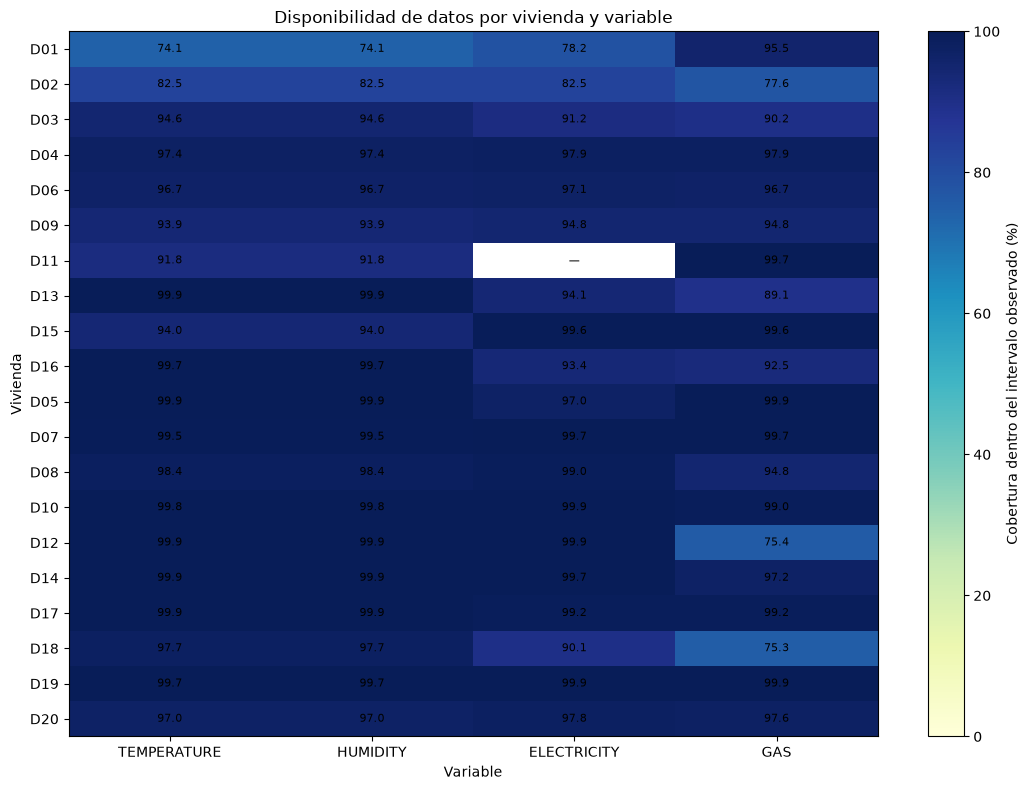

,Group,House,Variable,Coverage_pct,Observed_records,Expected_records,Start,End
0,UHI,D01,TEMPERATURE,74.09,33686,45468,2019-05-21 17:45:00,2020-09-06 08:30:00
1,UHI,D01,HUMIDITY,74.09,33686,45468,2019-05-21 17:45:00,2020-09-06 08:30:00
2,UHI,D01,ELECTRICITY,78.18,35547,45469,2019-05-21 17:15:00,2020-09-06 08:15:00
3,UHI,D01,GAS,95.47,23978,25116,2019-12-19 17:30:00,2020-09-06 08:15:00
4,UHI,D02,TEMPERATURE,82.50,43206,52370,2019-05-16 11:45:00,2020-11-12 00:00:00
5,UHI,D02,HUMIDITY,82.50,43206,52370,2019-05-16 11:45:00,2020-11-12 00:00:00
6,UHI,D02,ELECTRICITY,82.52,43280,52447,2019-05-16 11:30:00,2020-11-12 19:00:00
7,UHI,D02,GAS,77.60,40697,52447,2019-05-16 11:30:00,2020-11-12 19:00:00
8,UHI,D03,TEMPERATURE,94.57,35863,37921,2019-06-01 00:00:00,2020-06-30 00:00:00
9,UHI,D03,HUMIDITY,94.57,35863,37921,2019-06-01 00:00:00,2020-06-30 00:00:00


In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
variables_cobertura = ["TEMPERATURE", "HUMIDITY", "ELECTRICITY", "GAS"]
frecuencia = pd.Timedelta(minutes=15)

registros_cobertura = []

for (group, house), data_house in df_integrated.groupby(["Group", "House"]):
    for variable in variables_cobertura:
        serie = data_house[["DateTime", variable]].dropna().drop_duplicates(
            subset="DateTime"
        )

        if serie.empty:
            cobertura = np.nan
            inicio = pd.NaT
            fin = pd.NaT
            observados = 0
            esperados = 0
        else:
            inicio = serie["DateTime"].min()
            fin = serie["DateTime"].max()
            observados = serie["DateTime"].nunique()
            esperados = int((fin - inicio) / frecuencia) + 1
            cobertura = 100 * observados / esperados if esperados else np.nan

        registros_cobertura.append({
            "Group": group,
            "House": house,
            "Variable": variable,
            "Coverage_pct": cobertura,
            "Observed_records": observados,
            "Expected_records": esperados,
            "Start": inicio,
            "End": fin
        })

df_cobertura = pd.DataFrame(registros_cobertura)

orden_viviendas = (
    df_integrated[["Group", "House"]]
    .drop_duplicates()
    .sort_values(["Group", "House"])["House"]
    .tolist()
)

matriz_cobertura = (
    df_cobertura
    .pivot(index="House", columns="Variable", values="Coverage_pct")
    .reindex(index=orden_viviendas, columns=variables_cobertura)
)

fig, ax = plt.subplots(figsize=(11, 8))
valores = matriz_cobertura.to_numpy(dtype=float)
imagen = ax.imshow(valores, aspect="auto", cmap="YlGnBu", vmin=0, vmax=100)

ax.set_xticks(range(len(matriz_cobertura.columns)))
ax.set_xticklabels(matriz_cobertura.columns, rotation=0)
ax.set_yticks(range(len(matriz_cobertura.index)))
ax.set_yticklabels(matriz_cobertura.index)
ax.set_title("Disponibilidad de datos por vivienda y variable")
ax.set_xlabel("Variable")
ax.set_ylabel("Vivienda")

for fila in range(valores.shape[0]):
    for columna in range(valores.shape[1]):
        valor = valores[fila, columna]
        etiqueta = "—" if np.isnan(valor) else f"{valor:.1f}"
        ax.text(columna, fila, etiqueta, ha="center", va="center", fontsize=8)

barra = fig.colorbar(imagen, ax=ax)
barra.set_label("Cobertura dentro del intervalo observado (%)")
fig.tight_layout()
plt.show()

display(df_cobertura.round({"Coverage_pct": 2}).head(10))

**Interpretación:** los porcentajes permiten localizar series con menor continuidad dentro de su propio periodo registrado. No deben interpretarse como una comparación de cobertura sobre un calendario común: cada vivienda-variable puede tener fechas de inicio y fin diferentes. La frecuencia de 15 minutos es una referencia nominal.

In [65]:
# Crear carpeta de datos procesados
processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

# Guardar tabla integrada
output_path = processed_dir / "madrid_energy_integrated.csv"

df_integrated.to_csv(
    output_path,
    index=False
)

print("Archivo guardado:", output_path.resolve())
print("Tamaño:", round(output_path.stat().st_size / (1024**2), 2), "MB")

Archivo guardado: /Users/fyeray/Documents/Data Science/EDA-Monitorizacion-Energetica/data/processed/madrid_energy_integrated.csv
Tamaño: 59.75 MB


## Fase 5. Limpieza y control de calidad

Se realizan comprobaciones generales sobre el conjunto de datos integrado para identificar valores ausentes, registros duplicados y valores fuera de los rangos esperados.

In [66]:
# Variables principales
variables = [
    "TEMPERATURE",
    "HUMIDITY",
    "ELECTRICITY",
    "GAS"
]

# Resumen general
print("DIMENSIONES")
print(df_integrated.shape)

print("\nREGISTROS DUPLICADOS")
print(
    df_integrated.duplicated(
        subset=["Group", "House", "DateTime"]
    ).sum()
)

print("\nVALORES AUSENTES")
display(df_integrated[variables].isna().sum())

print("\nESTADÍSTICAS DESCRIPTIVAS")
display(df_integrated[variables].describe().T)

print("\nVALORES NEGATIVOS")
display(
    (df_integrated[variables] < 0).sum()
)

DIMENSIONES
(1075812, 11)

REGISTROS DUPLICADOS
0

VALORES AUSENTES


TEMPERATURE    338372
HUMIDITY       338372
ELECTRICITY     37514
GAS            110091
dtype: int64


ESTADÍSTICAS DESCRIPTIVAS


,count,mean,std,min,25%,50%,75%,max
TEMPERATURE,737440.0,23.652502,3.743176,11.00,20.90,22.96,26.44,45.20
HUMIDITY,737440.0,41.906817,10.860371,12.99,34.00,41.00,49.00,76.44
ELECTRICITY,1038298.0,0.075443,0.092931,-0.34,0.03,0.05,0.08,1.73
GAS,965721.0,0.171908,0.542337,-1.65,0.00,0.01,0.03,12.91



VALORES NEGATIVOS


TEMPERATURE     0
HUMIDITY        0
ELECTRICITY    26
GAS            16
dtype: int64

### Conclusión del control de calidad · Los datos están integrados, pero la cobertura es desigual

- No existen registros duplicados en el conjunto integrado.
- Se mantienen valores ausentes debido a las diferencias de cobertura temporal.
- Se identifican 26 valores negativos en electricidad y 16 en gas.
- Los valores negativos se conservan para evitar eliminar información sin conocer su origen.
- No se realizan imputaciones ni sustituciones por cero.

El conjunto de datos se considera preparado para iniciar el análisis exploratorio, teniendo en cuenta las limitaciones identificadas.

> **Guía de lectura:** cada apartado empieza por su hallazgo principal. Los gráficos descriptivos usan todos los datos disponibles; las asociaciones H01–H02 y comparaciones H03–H04 aplican una cobertura mínima del 75 % por variable y día. Los resultados de referencia proceden de la memoria y deben verificarse reejecutando este notebook con los CSV originales.

# Fase 6. Análisis exploratorio de datos

## 6.1. La temperatura se concentra en dos franjas y los consumos presentan valores extremos

Se analiza la distribución de temperatura, humedad, electricidad y gas mediante histogramas, con el objetivo de conocer sus valores habituales, dispersión y posibles observaciones extremas.

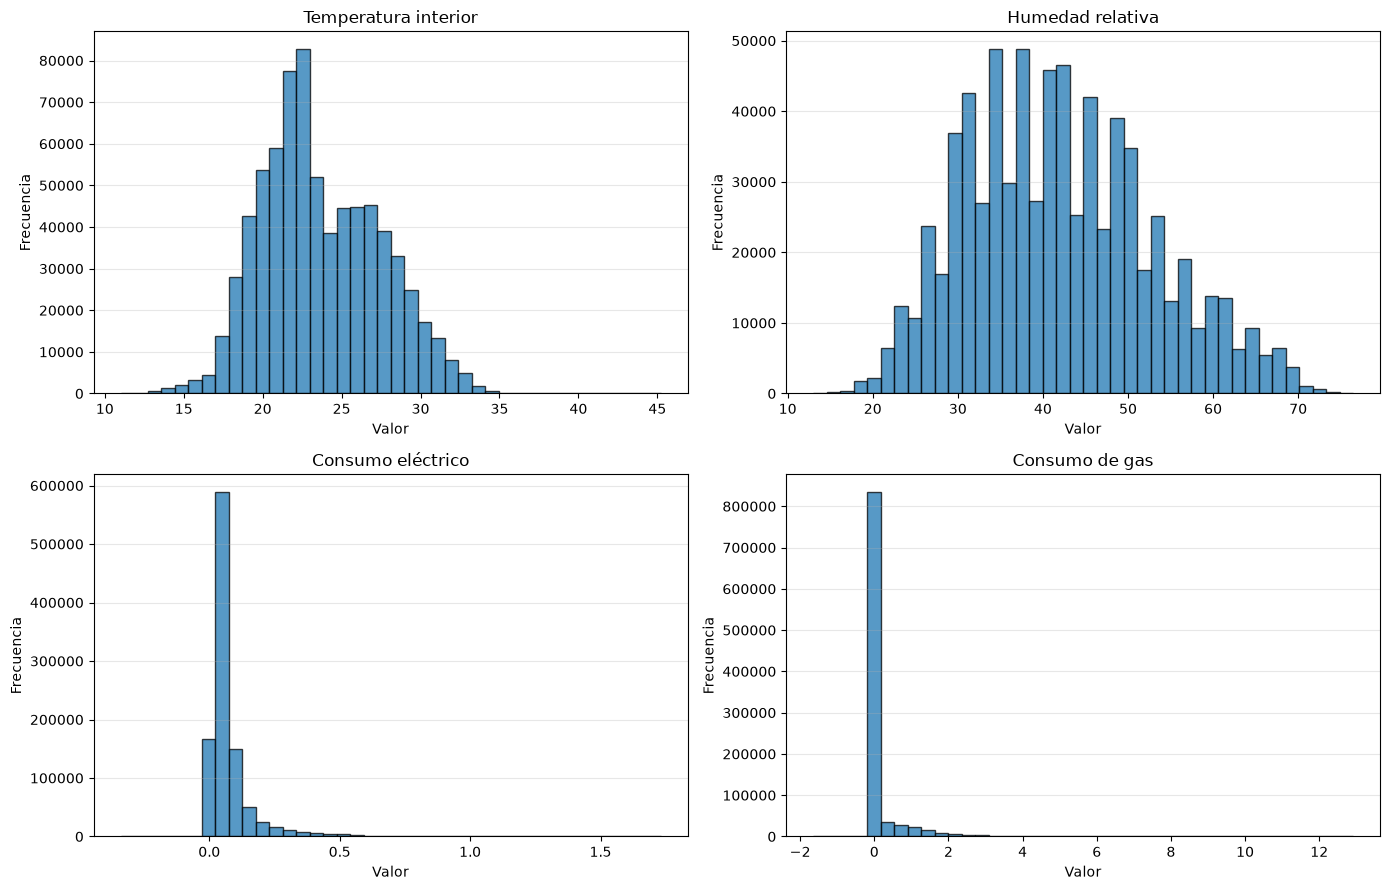

In [67]:
import matplotlib.pyplot as plt

variables = [
    "TEMPERATURE",
    "HUMIDITY",
    "ELECTRICITY",
    "GAS"
]

titles = [
    "Temperatura interior",
    "Humedad relativa",
    "Consumo eléctrico",
    "Consumo de gas"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, variable, title in zip(axes.flat, variables, titles):

    data = df_integrated[variable].dropna()

    ax.hist(data, bins=40, edgecolor="black", alpha=0.75)
    ax.set_title(title)
    ax.set_xlabel("Valor")
    ax.set_ylabel("Frecuencia")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Interpretación de las distribuciones

- Temperatura: distribución con dos zonas principales de concentración, aproximadamente entre 19-23 °C y 25-29 °C.
- Humedad: mayor concentración entre el 30 % y el 50 %, con una distribución extendida hacia valores superiores.
- Electricidad: distribución fuertemente asimétrica, con predominio de consumos bajos y una cola hacia valores elevados.
- Gas: elevada concentración de observaciones próximas a cero y una cola larga hacia valores positivos.

Los histogramas representan conjuntamente las 20 viviendas y todo el periodo disponible. Por tanto, no permiten atribuir las diferencias observadas a factores estacionales o características particulares de los hogares.

## 6.2. El gas aumenta en periodos fríos; la electricidad no muestra un patrón tan claro

Se agregan los registros de 15 minutos a frecuencia diaria. Se calculan medias para temperatura y humedad y sumas para electricidad y gas, manteniendo los valores ausentes cuando no existen observaciones disponibles.

**Dos usos de los datos diarios:** `df_daily_full` conserva los días con registros disponibles para gráficos de evolución; `df_daily` exige al menos 72 mediciones por variable y día (75 % de cobertura) para correlaciones y comparaciones. No se imputan valores ausentes.

In [68]:
# Agregación diaria por vivienda: serie descriptiva y versión comparable (≥75 % de cobertura)
df_integrated["Date_day"] = df_integrated["DateTime"].dt.floor("D")

# 96 intervalos nominales de 15 minutos/día; 72 equivalen al 75 %.
MIN_REGISTROS_DIA = 72
variables_eda = ["TEMPERATURE", "HUMIDITY", "ELECTRICITY", "GAS"]

df_daily_full = (
    df_integrated.groupby(["Group", "House", "Date_day"])
    .agg(
        TEMPERATURE=("TEMPERATURE", "mean"),
        HUMIDITY=("HUMIDITY", "mean"),
        ELECTRICITY=("ELECTRICITY", lambda x: x.sum(min_count=1)),
        GAS=("GAS", lambda x: x.sum(min_count=1)),
        **{f"n_{v}": (v, "count") for v in variables_eda}
    ).reset_index()
)

# El filtro se aplica por variable (no elimina el día entero).
# Las comparaciones y correlaciones emplean exclusivamente df_daily.
df_daily = df_daily_full.copy()
for variable in variables_eda:
    df_daily.loc[df_daily[f"n_{variable}"] < MIN_REGISTROS_DIA, variable] = float("nan")

print("Viviendas:", df_daily["House"].nunique())
print("Filas diarias:", len(df_daily))
print("Días válidos por variable (cobertura ≥75 %):")
display(df_daily[variables_eda].notna().sum().to_frame("días-vivienda válidos"))
display(df_daily.head())

Dimensiones: (11268, 7)
Viviendas: 20


,Group,House,Date_day,TEMPERATURE,HUMIDITY,ELECTRICITY,GAS
0,UHI,D01,2019-05-21,24.412800,35.502000,2.55,NaN
1,UHI,D01,2019-05-22,24.320208,37.337708,4.80,NaN
2,UHI,D01,2019-05-23,24.853854,36.069479,6.64,NaN
3,UHI,D01,2019-05-24,25.363542,37.272396,5.74,NaN
4,UHI,D01,2019-05-25,25.289375,36.958229,6.34,NaN


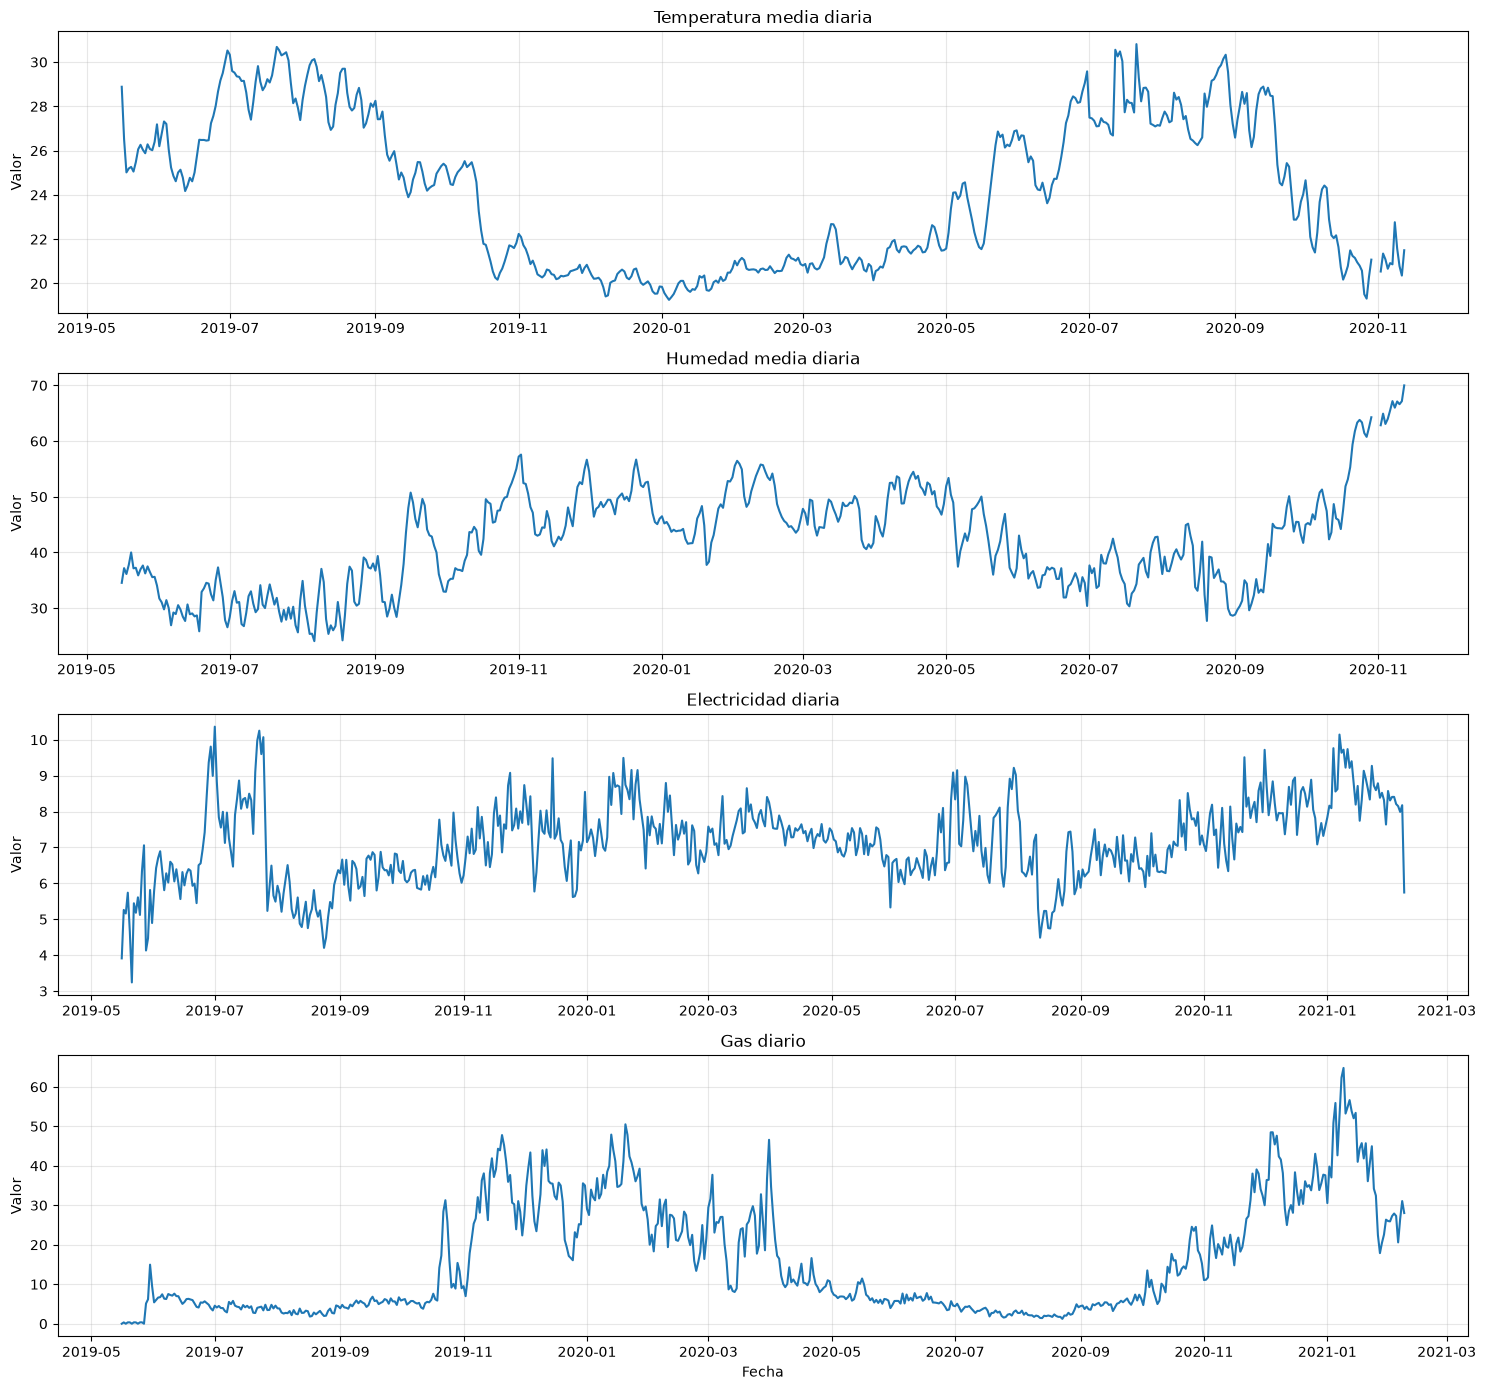

In [69]:
import matplotlib.pyplot as plt

variables = [
    "TEMPERATURE",
    "HUMIDITY",
    "ELECTRICITY",
    "GAS"
]

titles = [
    "Temperatura media diaria",
    "Humedad media diaria",
    "Electricidad diaria",
    "Gas diario"
]

fig, axes = plt.subplots(4, 1, figsize=(15, 14))

for ax, variable, title in zip(axes, variables, titles):

    daily_mean = (
        df_daily_full.groupby("Date_day")[variable]
        .mean()
    )

    ax.plot(daily_mean.index, daily_mean.values)
    ax.set_title(title)
    ax.set_ylabel("Valor")
    ax.grid(alpha=0.3)

plt.xlabel("Fecha")
plt.tight_layout()
plt.show()

### Índice base 100: las variables evolucionan a ritmos distintos

Para comparar la evolución temporal de variables expresadas en unidades diferentes, se construye un índice base 100. Para cada variable, el valor 100 representa su propia media diaria a lo largo del periodo observado; por ejemplo, 120 indica un valor un 20 % superior a esa media y 80 un valor un 20 % inferior.

El cálculo parte de `df_daily`, que contiene una fila por vivienda y día:
- Temperatura y humedad: media de las mediciones de 15 minutos de cada vivienda durante el día.
- Electricidad y gas: suma de las mediciones de cada vivienda durante el día.

A continuación, para cada fecha se calcula la media entre las viviendas que tienen un valor disponible. También se cuenta cuántas viviendas contribuyen a cada variable y fecha.

**Precauciones de interpretación:** el índice permite comparar cambios relativos, no magnitudes físicas. Las cuatro curvas no deben interpretarse como si compartieran unidades. Además, la composición de viviendas disponibles puede variar entre fechas y variables; por tanto, una variación del índice puede reflejar tanto cambios reales como cambios en las viviendas que aportan datos. La visualización es descriptiva y no demuestra causalidad.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Variables que se mostrarán en el índice conjunto
variables_indice = [
    "TEMPERATURE",
    "HUMIDITY",
    "ELECTRICITY",
    "GAS"
]

nombres_variables = {
    "TEMPERATURE": "Temperatura",
    "HUMIDITY": "Humedad",
    "ELECTRICITY": "Electricidad",
    "GAS": "Gas"
}

# Media diaria entre viviendas disponibles para cada variable
media_diaria_viviendas = (
    df_daily_full
    .groupby("Date_day")[variables_indice]
    .mean()
    .sort_index()
)

# Número de viviendas que aportan datos en cada fecha y variable
viviendas_disponibles = (
    df_daily_full
    .groupby("Date_day")[variables_indice]
    .count()
    .sort_index()
)

# Índice base 100: la media temporal de cada serie equivale a 100
media_periodo = media_diaria_viviendas.mean()
indice_base_100 = media_diaria_viviendas.divide(media_periodo).multiply(100)

# Mostrar las cuatro curvas en un mismo eje y la cobertura en un panel inferior
fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(16, 10),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]}
)

for variable in variables_indice:
    ax1.plot(
        indice_base_100.index,
        indice_base_100[variable],
        label=nombres_variables[variable],
        linewidth=1.4,
        alpha=0.9
    )

ax1.axhline(100, color="black", linestyle="--", linewidth=1, alpha=0.7)
ax1.set_title("Evolución conjunta de las variables · Índice base 100")
ax1.set_ylabel("Índice (media del periodo = 100)")
ax1.legend(ncol=4, loc="upper center")
ax1.grid(alpha=0.25)

for variable in variables_indice:
    ax2.plot(
        viviendas_disponibles.index,
        viviendas_disponibles[variable],
        label=nombres_variables[variable],
        linewidth=1.1
    )

ax2.set_title("Viviendas disponibles por fecha y variable")
ax2.set_ylabel("N.º de viviendas")
ax2.set_xlabel("Fecha")
ax2.set_ylim(bottom=0)
ax2.grid(alpha=0.25)
ax2.legend(ncol=4, loc="upper center")

plt.tight_layout()
plt.show()

# Tabla resumen para comprobar las medias de referencia y la cobertura
resumen_indice = pd.DataFrame({
    "Media diaria de referencia": media_periodo,
    "Fechas con datos": media_diaria_viviendas.count(),
    "Media de viviendas disponibles": viviendas_disponibles.mean()
}).rename(index=nombres_variables)

display(resumen_indice.round(2))

### Interpretación de la evolución temporal

- La temperatura interior presenta un patrón estacional, con valores más elevados durante los meses de verano y más bajos durante el invierno.
- La humedad relativa muestra una evolución temporal diferente, con valores generalmente más elevados durante parte del otoño y el invierno.
- El consumo eléctrico presenta oscilaciones a lo largo del periodo, sin una estacionalidad visual tan marcada.
- El consumo de gas muestra un patrón estacional más evidente, con incrementos durante los meses fríos y reducciones durante los meses cálidos.

Estos resultados son descriptivos. La disponibilidad variable de datos entre viviendas y periodos debe tenerse en cuenta al interpretar las tendencias.

## 6.3. La electricidad alcanza picos hacia las 14:00 y 21:00; el gas, hacia las 20:00

Se analiza la distribución del consumo eléctrico y de gas a lo largo de las 24 horas del día, agregando los registros de 15 minutos a intervalos horarios.

In [70]:
# Crear variables temporales
df_integrated["Date_day"] = df_integrated["DateTime"].dt.date
df_integrated["Hour"] = df_integrated["DateTime"].dt.hour

# Calcular consumo horario por vivienda y día
df_hourly = (
    df_integrated
    .groupby(["Group", "House", "Date_day", "Hour"])
    .agg(
        ELECTRICITY=("ELECTRICITY", lambda x: x.sum(min_count=1)),
        GAS=("GAS", lambda x: x.sum(min_count=1)),
        N_ELECTRICITY=("ELECTRICITY", "count"),
        N_GAS=("GAS", "count")
    )
    .reset_index()
)

# Conservar horas completas: cuatro registros de 15 minutos
df_hourly.loc[df_hourly["N_ELECTRICITY"] != 4, "ELECTRICITY"] = float("nan")
df_hourly.loc[df_hourly["N_GAS"] != 4, "GAS"] = float("nan")

print("Dimensiones:", df_hourly.shape)

Dimensiones: (269128, 8)


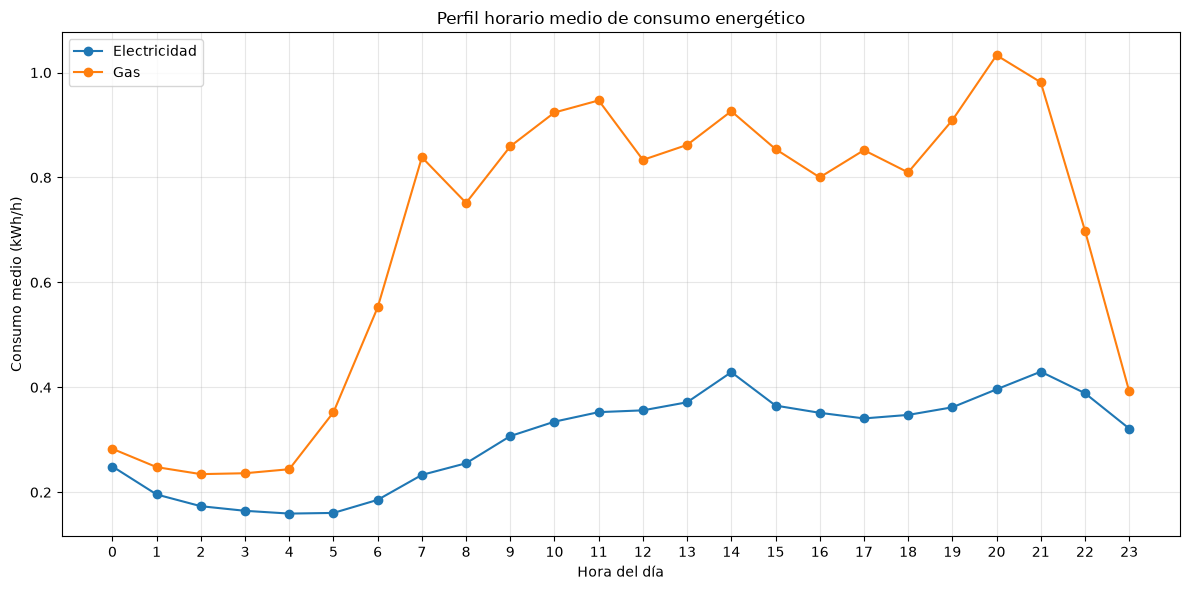

In [71]:
import matplotlib.pyplot as plt

hourly_profile = (
    df_hourly.groupby("Hour")[["ELECTRICITY", "GAS"]]
    .mean()
)

plt.figure(figsize=(12, 6))

plt.plot(
    hourly_profile.index,
    hourly_profile["ELECTRICITY"],
    marker="o",
    label="Electricidad"
)

plt.plot(
    hourly_profile.index,
    hourly_profile["GAS"],
    marker="o",
    label="Gas"
)

plt.xticks(range(24))
plt.xlabel("Hora del día")
plt.ylabel("Consumo medio (kWh/h)")
plt.title("Perfil horario medio de consumo energético")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

### Interpretación del perfil horario de consumo

- El consumo eléctrico presenta sus valores más bajos durante la madrugada y aumenta progresivamente durante la mañana.
- Se observan dos máximos relativos de electricidad, aproximadamente a las 14:00 y a las 21:00.
- El consumo de gas aumenta notablemente a partir de las 6:00 y alcanza su máximo alrededor de las 20:00.
- El gas presenta una variabilidad horaria más marcada que la electricidad.

Los resultados muestran diferencias entre los perfiles horarios de ambas fuentes energéticas. No obstante, no permiten atribuir los patrones observados a actividades concretas de los ocupantes.

## 6.4. H01 · A menor temperatura interior, suele observarse más consumo de gas

Se estudia la asociación entre la temperatura interior media diaria y el consumo diario de electricidad y gas. Las correlaciones se calculan individualmente por vivienda y posteriormente se resumen para evitar tratar las observaciones temporales como independientes entre hogares.

In [72]:
from scipy.stats import spearmanr

results = []

for (group, house), data in df_daily.groupby(["Group", "House"]):

    for energy in ["ELECTRICITY", "GAS"]:

        paired = data[["TEMPERATURE", energy]].dropna()

        # Se exige un mínimo de 30 días con ambas variables disponibles.
        if len(paired) < 30:
            continue

        correlation, p_value = spearmanr(
            paired["TEMPERATURE"],
            paired[energy]
        )

        results.append({
            "Group": group,
            "House": house,
            "Energy": energy,
            "Observations": len(paired),
            "Correlation": correlation,
            "P_value": p_value
        })

df_correlations = pd.DataFrame(results)

display(df_correlations.round(3))

,Group,House,Energy,Observations,Correlation,P_value
0,UHI,D01,ELECTRICITY,375,0.601,0.000
1,UHI,D01,GAS,260,-0.809,0.000
2,UHI,D02,ELECTRICITY,468,-0.361,0.000
3,UHI,D02,GAS,441,0.119,0.012
4,UHI,D03,ELECTRICITY,376,0.221,0.000
5,UHI,D03,GAS,356,-0.351,0.000
6,UHI,D04,ELECTRICITY,392,-0.484,0.000
7,UHI,D04,GAS,392,-0.446,0.000
8,UHI,D06,ELECTRICITY,391,-0.568,0.000
9,UHI,D06,GAS,391,-0.756,0.000


In [73]:
# Resumen de correlaciones H01 por tipo de consumo
correlation_summary = (
    df_correlations
    .groupby("Energy")["Correlation"]
    .agg(
        Homes="count",
        Median="median",
        Mean="mean",
        Minimum="min",
        Maximum="max"
    )
)

display(correlation_summary.round(3))

print("Viviendas incluidas por consumo:")
display(
    df_correlations.groupby("Energy")["House"]
    .nunique()
    .rename("Viviendas")
    .to_frame()
)

,Homes,Median,Mean,Minimum,Maximum
Energy,,,,,
ELECTRICITY,19,-0.141,-0.151,-0.602,0.601
GAS,20,-0.703,-0.525,-0.837,0.119


Viviendas incluidas por consumo:


,Viviendas
Energy,
ELECTRICITY,19
GAS,20


## Visualización adicional H01: correlación de temperatura por vivienda

Se representan las correlaciones de Spearman individuales ya calculadas en `df_correlations`. Cada barra corresponde a una vivienda; el color distingue UHI y UP. La línea vertical en cero separa asociaciones negativas y positivas.

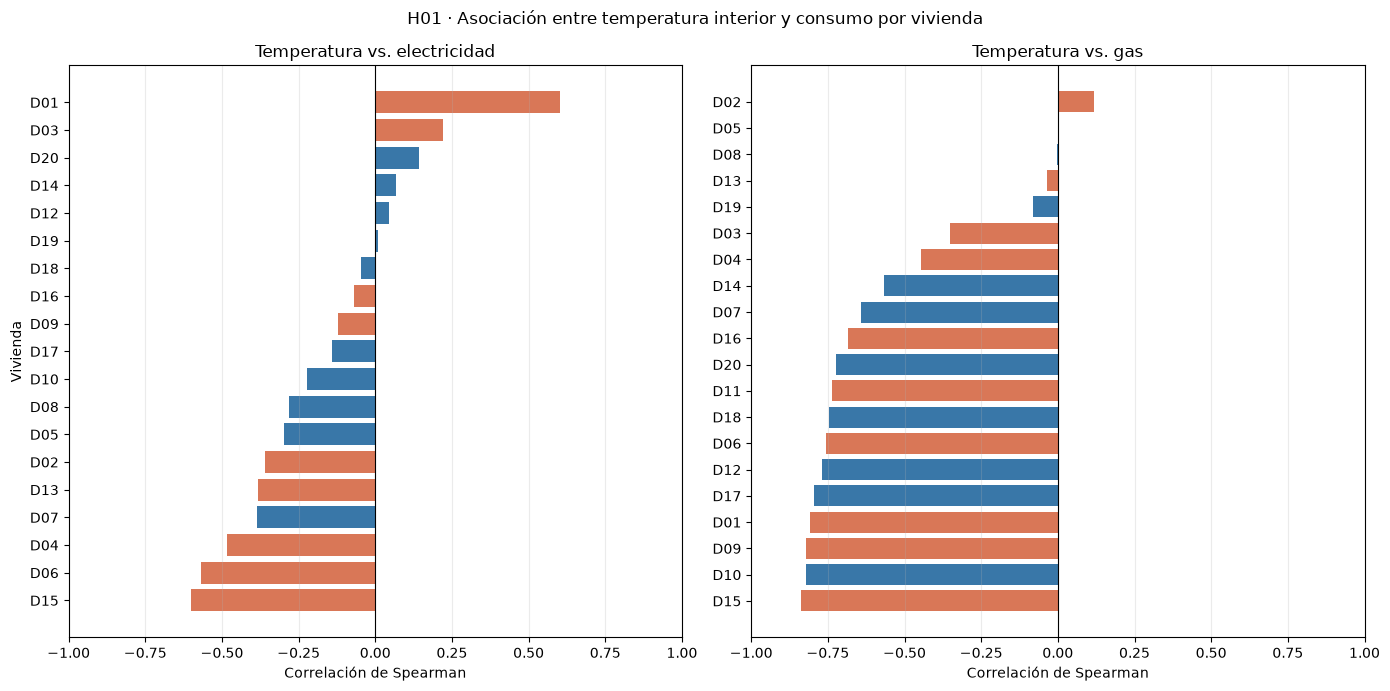

,Group,House,Energy,Observations,Correlation
15,UHI,D15,ELECTRICITY,394,-0.602
8,UHI,D06,ELECTRICITY,391,-0.568
6,UHI,D04,ELECTRICITY,392,-0.484
21,UP,D07,ELECTRICITY,396,-0.386
13,UHI,D13,ELECTRICITY,369,-0.382
2,UHI,D02,ELECTRICITY,468,-0.361
19,UP,D05,ELECTRICITY,396,-0.299
23,UP,D08,ELECTRICITY,392,-0.280
25,UP,D10,ELECTRICITY,396,-0.222
31,UP,D17,ELECTRICITY,396,-0.141


In [74]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharex=True)

colores_grupo = {"UHI": "#D97757", "UP": "#3977A8"}
titulos = {
    "ELECTRICITY": "Temperatura vs. electricidad",
    "GAS": "Temperatura vs. gas"
}

for ax, energy in zip(axes, ["ELECTRICITY", "GAS"]):
    datos = df_correlations[df_correlations["Energy"] == energy].copy()
    datos = datos.sort_values("Correlation")

    colores = datos["Group"].map(colores_grupo)
    ax.barh(datos["House"], datos["Correlation"], color=colores)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlim(-1, 1)
    ax.set_title(titulos[energy])
    ax.set_xlabel("Correlación de Spearman")
    ax.grid(axis="x", alpha=0.25)

axes[0].set_ylabel("Vivienda")
fig.suptitle("H01 · Asociación entre temperatura interior y consumo por vivienda")
fig.tight_layout()
plt.show()

display(
    df_correlations[["Group", "House", "Energy", "Observations", "Correlation"]]
    .sort_values(["Energy", "Correlation"])
    .round(3)
)

**Interpretación:** la figura permite comprobar si la asociación negativa observada en la mediana se repite en la mayoría de viviendas o está condicionada por algunos hogares. La correlación describe asociación monotónica, no causalidad. Las viviendas sin suficientes observaciones emparejadas no aparecen porque el cálculo original exige al menos 30 días válidos.

### Resultados H01: Temperatura y consumo energético

Los resultados cuantitativos de H01 se muestran en la tabla `correlation_summary`, calculada directamente a partir de las correlaciones individuales de Spearman de `df_correlations`.

La mediana resume la asociación típica entre viviendas; la media, el mínimo y el máximo permiten observar la dispersión de los resultados. La interpretación debe basarse en los valores que produzca la ejecución actual del notebook, no en cifras copiadas de una presentación anterior.

En términos generales, una correlación negativa indica que, dentro de una vivienda, los días con mayor temperatura interior tienden a coincidir con menor consumo diario. Esto describe una asociación monotónica y no demuestra causalidad. La estacionalidad y otras variables no observadas pueden influir en el patrón.

La hipótesis H01 recibe apoyo descriptivo en la medida que indiquen las medianas y la distribución de correlaciones obtenidas al ejecutar el análisis.

**Resultado de referencia de la memoria revisada (con cobertura mínima):** mediana temperatura–gas = −0,668 (20 viviendas); temperatura–electricidad = −0,197 (19 viviendas). Comprobar que la ejecución del notebook reproduce estas cifras antes de citar resultados nuevos.

## 6.5. H02 · La humedad se asocia más con el gas que con la electricidad

Se estudia la asociación entre la humedad relativa media diaria y el consumo diario de electricidad y gas. Se calculan correlaciones de Spearman individualmente por vivienda y se resumen los resultados.

In [75]:
from scipy.stats import spearmanr

results_humidity = []

for (group, house), data in df_daily.groupby(["Group", "House"]):

    for energy in ["ELECTRICITY", "GAS"]:

        paired = data[["HUMIDITY", energy]].dropna()

        # Se exige un mínimo de 30 días con ambas variables disponibles.
        if len(paired) < 30:
            continue

        correlation, p_value = spearmanr(
            paired["HUMIDITY"],
            paired[energy]
        )

        results_humidity.append({
            "Group": group,
            "House": house,
            "Energy": energy,
            "Observations": len(paired),
            "Correlation": correlation,
            "P_value": p_value
        })

df_correlations_humidity = pd.DataFrame(results_humidity)

display(df_correlations_humidity.round(3))

,Group,House,Energy,Observations,Correlation,P_value
0,UHI,D01,ELECTRICITY,375,-0.228,0.000
1,UHI,D01,GAS,260,0.437,0.000
2,UHI,D02,ELECTRICITY,468,0.370,0.000
3,UHI,D02,GAS,441,-0.162,0.001
4,UHI,D03,ELECTRICITY,376,-0.079,0.125
5,UHI,D03,GAS,356,0.385,0.000
6,UHI,D04,ELECTRICITY,392,0.498,0.000
7,UHI,D04,GAS,392,0.407,0.000
8,UHI,D06,ELECTRICITY,391,0.524,0.000
9,UHI,D06,GAS,391,0.649,0.000


In [76]:
# Resumen de correlaciones H02 por tipo de consumo
humidity_summary = (
    df_correlations_humidity
    .groupby("Energy")["Correlation"]
    .agg(
        Homes="count",
        Median="median",
        Mean="mean",
        Minimum="min",
        Maximum="max"
    )
)

display(humidity_summary.round(3))

print("Viviendas incluidas por consumo:")
display(
    df_correlations_humidity.groupby("Energy")["House"]
    .nunique()
    .rename("Viviendas")
    .to_frame()
)

,Homes,Median,Mean,Minimum,Maximum
Energy,,,,,
ELECTRICITY,19,0.165,0.192,-0.228,0.524
GAS,20,0.396,0.319,-0.162,0.734


Viviendas incluidas por consumo:


,Viviendas
Energy,
ELECTRICITY,19
GAS,20


## Visualización adicional H02: correlación de humedad por vivienda

Se utiliza el mismo criterio gráfico que en H01, ahora con los resultados de `df_correlations_humidity`. Esto facilita comparar la heterogeneidad entre viviendas y distinguir las asociaciones positivas de las negativas.

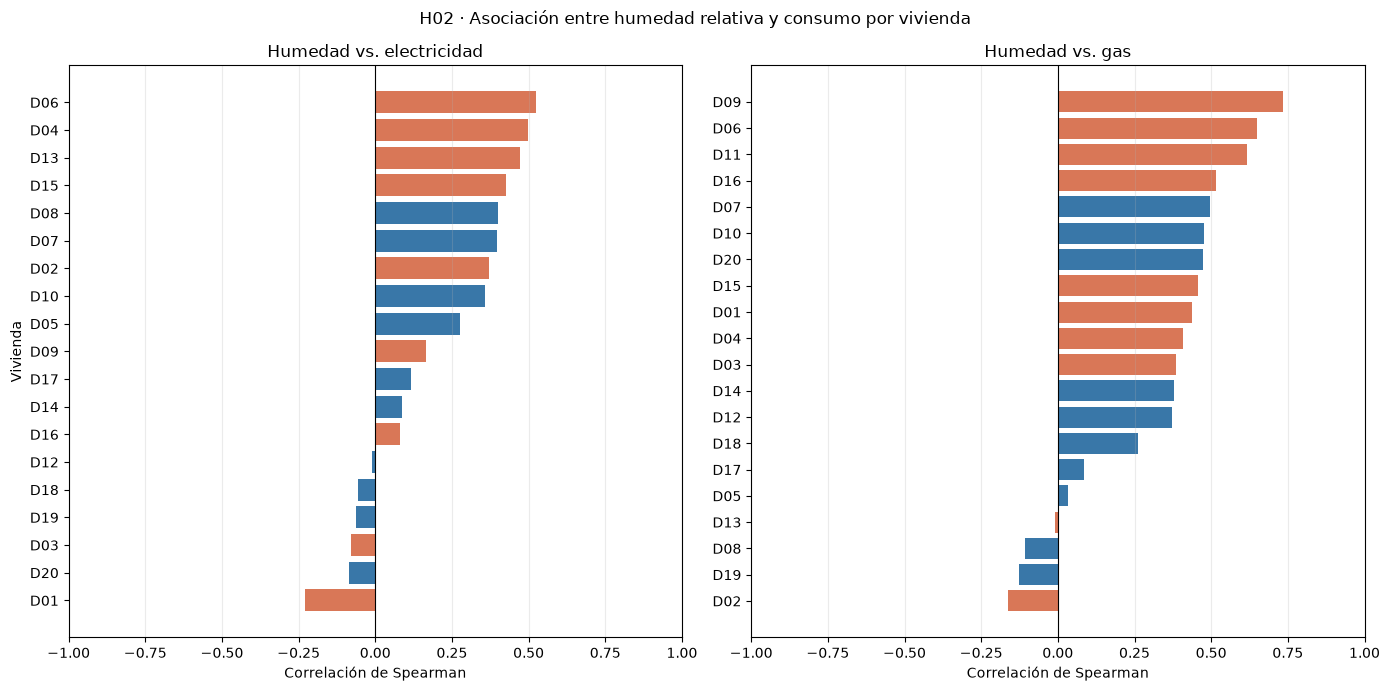

,Group,House,Energy,Observations,Correlation
0,UHI,D01,ELECTRICITY,375,-0.228
37,UP,D20,ELECTRICITY,385,-0.085
4,UHI,D03,ELECTRICITY,376,-0.079
35,UP,D19,ELECTRICITY,396,-0.062
33,UP,D18,ELECTRICITY,396,-0.057
27,UP,D12,ELECTRICITY,396,-0.011
17,UHI,D16,ELECTRICITY,394,0.081
29,UP,D14,ELECTRICITY,396,0.087
31,UP,D17,ELECTRICITY,396,0.116
10,UHI,D09,ELECTRICITY,374,0.165


In [77]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharex=True)

titulos_humedad = {
    "ELECTRICITY": "Humedad vs. electricidad",
    "GAS": "Humedad vs. gas"
}

for ax, energy in zip(axes, ["ELECTRICITY", "GAS"]):
    datos = df_correlations_humidity[
        df_correlations_humidity["Energy"] == energy
    ].copy()
    datos = datos.sort_values("Correlation")

    colores = datos["Group"].map(colores_grupo)
    ax.barh(datos["House"], datos["Correlation"], color=colores)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlim(-1, 1)
    ax.set_title(titulos_humedad[energy])
    ax.set_xlabel("Correlación de Spearman")
    ax.grid(axis="x", alpha=0.25)

axes[0].set_ylabel("Vivienda")
fig.suptitle("H02 · Asociación entre humedad relativa y consumo por vivienda")
fig.tight_layout()
plt.show()

display(
    df_correlations_humidity[
        ["Group", "House", "Energy", "Observations", "Correlation"]
    ]
    .sort_values(["Energy", "Correlation"])
    .round(3)
)

**Interpretación:** se observa la distribución de correlaciones individuales detrás de las medianas de H02. Una mediana positiva no implica que todas las viviendas presenten una relación positiva. La figura no permite establecer causalidad.

### Resultados H02: Humedad y consumo energético

Los resultados cuantitativos de H02 se muestran en la tabla `humidity_summary`, calculada directamente a partir de las correlaciones individuales de Spearman de `df_correlations_humidity`.

La mediana resume la asociación típica entre viviendas. La media, el mínimo y el máximo ayudan a identificar la heterogeneidad entre hogares. La interpretación debe basarse en los valores que produzca la ejecución actual del notebook.

Una correlación positiva indica que, dentro de una vivienda, los días con mayor humedad interior tienden a coincidir con mayor consumo diario. Una mediana positiva no significa que todas las viviendas presenten una correlación positiva.

El análisis es descriptivo: no permite identificar el mecanismo de la asociación ni establecer causalidad. La hipótesis H02 recibe el grado de apoyo que indiquen las medianas y la distribución de correlaciones obtenidas.

**Resultado de referencia de la memoria revisada (con cobertura mínima):** mediana humedad–gas = +0,403 (20 viviendas); humedad–electricidad = +0,179 (19 viviendas). Comprobar los valores tras ejecutar el notebook.

## H01 y H02 · La relación más marcada es la de temperatura y gas

Este apartado reúne en una única tabla y una figura las medianas de las correlaciones de Spearman calculadas por vivienda para las cuatro combinaciones analizadas:

- H01: temperatura interior frente a electricidad y gas.
- H02: humedad relativa interior frente a electricidad y gas.

Los valores se calculan a partir de `df_correlations` y `df_correlations_humidity`; no se introducen manualmente. El número de viviendas puede variar entre combinaciones debido a la disponibilidad de datos y al requisito mínimo de 30 días emparejados.

In [78]:
# Construir un resumen conjunto a partir de las correlaciones individuales
summary_h01 = (
    df_correlations
    .groupby("Energy")["Correlation"]
    .agg(Median="median", Homes="count")
    .reset_index()
)
summary_h01["Hypothesis"] = "H01 · Temperatura"

summary_h02 = (
    df_correlations_humidity
    .groupby("Energy")["Correlation"]
    .agg(Median="median", Homes="count")
    .reset_index()
)
summary_h02["Hypothesis"] = "H02 · Humedad"

df_association_summary = pd.concat(
    [summary_h01, summary_h02],
    ignore_index=True
)

# Orden explícito para facilitar la lectura y la comparación
energy_order = ["ELECTRICITY", "GAS"]
hypothesis_order = ["H01 · Temperatura", "H02 · Humedad"]

df_association_summary["Energy"] = pd.Categorical(
    df_association_summary["Energy"],
    categories=energy_order,
    ordered=True
)
df_association_summary["Hypothesis"] = pd.Categorical(
    df_association_summary["Hypothesis"],
    categories=hypothesis_order,
    ordered=True
)

df_association_summary = df_association_summary.sort_values(
    ["Hypothesis", "Energy"]
).reset_index(drop=True)

display(
    df_association_summary.assign(
        Energy=df_association_summary["Energy"].astype(str),
        Hypothesis=df_association_summary["Hypothesis"].astype(str)
    ).round(3)
)

,Energy,Median,Homes,Hypothesis
0,ELECTRICITY,-0.141,19,H01 · Temperatura
1,GAS,-0.703,20,H01 · Temperatura
2,ELECTRICITY,0.165,19,H02 · Humedad
3,GAS,0.396,20,H02 · Humedad


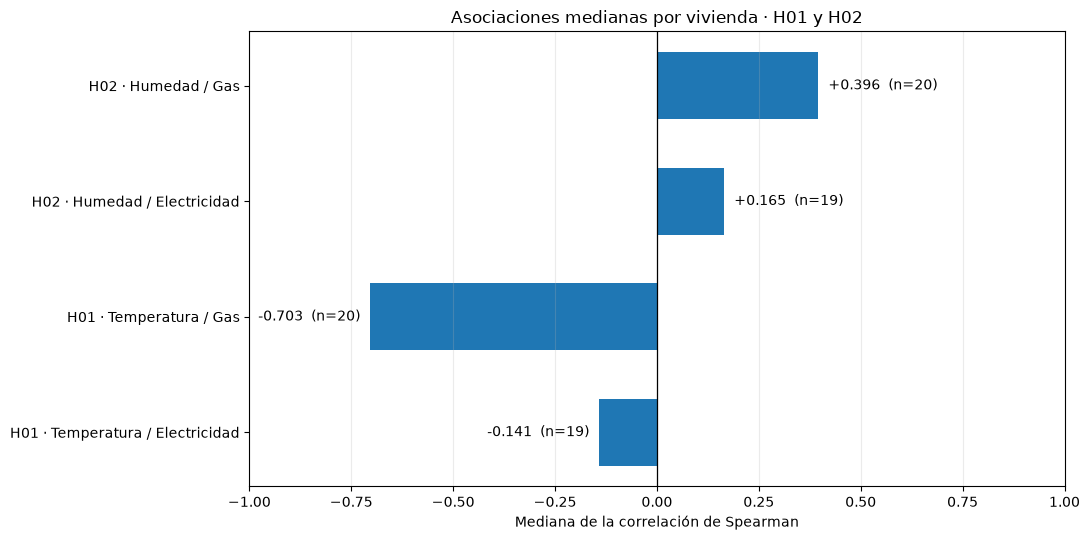

In [79]:
# Representar las medianas de Spearman de H01 y H02
import numpy as np
import matplotlib.pyplot as plt

labels = [
    "H01 · Temperatura / Electricidad",
    "H01 · Temperatura / Gas",
    "H02 · Humedad / Electricidad",
    "H02 · Humedad / Gas"
]

plot_data = df_association_summary.copy()
energy_labels = {
    "ELECTRICITY": "Electricidad",
    "GAS": "Gas"
}
plot_data["Label"] = (
    plot_data["Hypothesis"].astype(str)
    + " / "
    + plot_data["Energy"].astype(str).map(energy_labels)
)

# Mantener el orden de lectura definido arriba
plot_data["Label"] = pd.Categorical(
    plot_data["Label"],
    categories=labels,
    ordered=True
)
plot_data = plot_data.sort_values("Label")

fig, ax = plt.subplots(figsize=(11, 5.5))
y_positions = np.arange(len(plot_data))

bars = ax.barh(
    y_positions,
    plot_data["Median"],
    height=0.58
)

ax.set_yticks(y_positions)
ax.set_yticklabels(plot_data["Label"])
ax.axvline(0, color="black", linewidth=0.9)
ax.set_xlim(-1, 1)
ax.set_xlabel("Mediana de la correlación de Spearman")
ax.set_title("Asociaciones medianas por vivienda · H01 y H02")
ax.grid(axis="x", alpha=0.25)

for bar, value, homes in zip(
    bars,
    plot_data["Median"],
    plot_data["Homes"]
):
    x_text = value + (0.025 if value >= 0 else -0.025)
    alignment = "left" if value >= 0 else "right"
    ax.text(
        x_text,
        bar.get_y() + bar.get_height() / 2,
        f"{value:+.3f}  (n={homes})",
        va="center",
        ha=alignment
    )

fig.tight_layout()
plt.show()

### Interpretación del resumen conjunto

La figura permite comparar la dirección y la intensidad de las asociaciones medianas de H01 y H02. Los valores positivos indican asociaciones directas y los negativos, asociaciones inversas. La etiqueta `n` indica cuántas viviendas aportan una correlación válida a cada combinación.

La mediana se calcula sobre las correlaciones individuales de las viviendas, no sobre todos los registros diarios agrupados entre hogares. Por ello, cada vivienda válida aporta una correlación al resumen. Las diferencias de cobertura y la exclusión de viviendas con menos de 30 días emparejados deben tenerse en cuenta.

**Control metodológico:** para las correlaciones se exigen al menos 72 de los 96 registros diarios nominales por variable. La regla reduce el sesgo de días muy incompletos, aunque no controla la estacionalidad ni permite afirmar causalidad.

## 6.6. H03 · UHI presenta mayor humedad y gas; temperatura y electricidad son similares

Se comparan las condiciones ambientales interiores y el consumo energético de las viviendas pertenecientes a los grupos UHI y UP.

La vivienda constituye la unidad de análisis para evitar que los hogares con mayor número de registros tengan más peso en la comparación.

In [80]:
# Calcular indicadores medios por vivienda
df_house = (
    df_daily
    .groupby(["Group", "House"])
    .agg(
        TEMPERATURE=("TEMPERATURE", "mean"),
        HUMIDITY=("HUMIDITY", "mean"),
        ELECTRICITY=("ELECTRICITY", "mean"),
        GAS=("GAS", "mean")
    )
    .reset_index()
)

display(df_house.round(2))

,Group,House,TEMPERATURE,HUMIDITY,ELECTRICITY,GAS
0,UHI,D01,24.36,42.02,9.39,14.81
1,UHI,D02,24.66,49.66,5.30,1.28
2,UHI,D03,21.16,50.04,6.62,15.16
3,UHI,D04,22.73,45.90,5.65,15.38
4,UHI,D06,23.41,42.31,8.19,38.13
5,UHI,D09,23.25,44.21,8.43,21.49
6,UHI,D11,21.79,50.72,NaN,0.39
7,UHI,D13,24.21,44.68,6.57,0.16
8,UHI,D15,23.95,35.25,2.95,30.03
9,UHI,D16,25.26,37.32,13.89,38.60


In [81]:
# Resumen por grupo
group_comparison = (
    df_house
    .groupby("Group")[
        ["TEMPERATURE", "HUMIDITY", "ELECTRICITY", "GAS"]
    ]
    .agg(["mean", "median", "std"])
)

display(group_comparison.round(2))

TEMPERATURE              HUMIDITY              ELECTRICITY               \
             mean median   std     mean median   std        mean median   std   
Group                                                                           
UHI         23.48  23.68  1.29    44.21  44.45  5.22        7.44   6.62  3.09   
UP          23.78  23.74  0.79    39.69  39.04  3.16        6.95   6.19  3.28   

         GAS                
        mean median    std  
Group                       
UHI    17.54  15.27  14.60  
UP     12.76  11.87   8.94

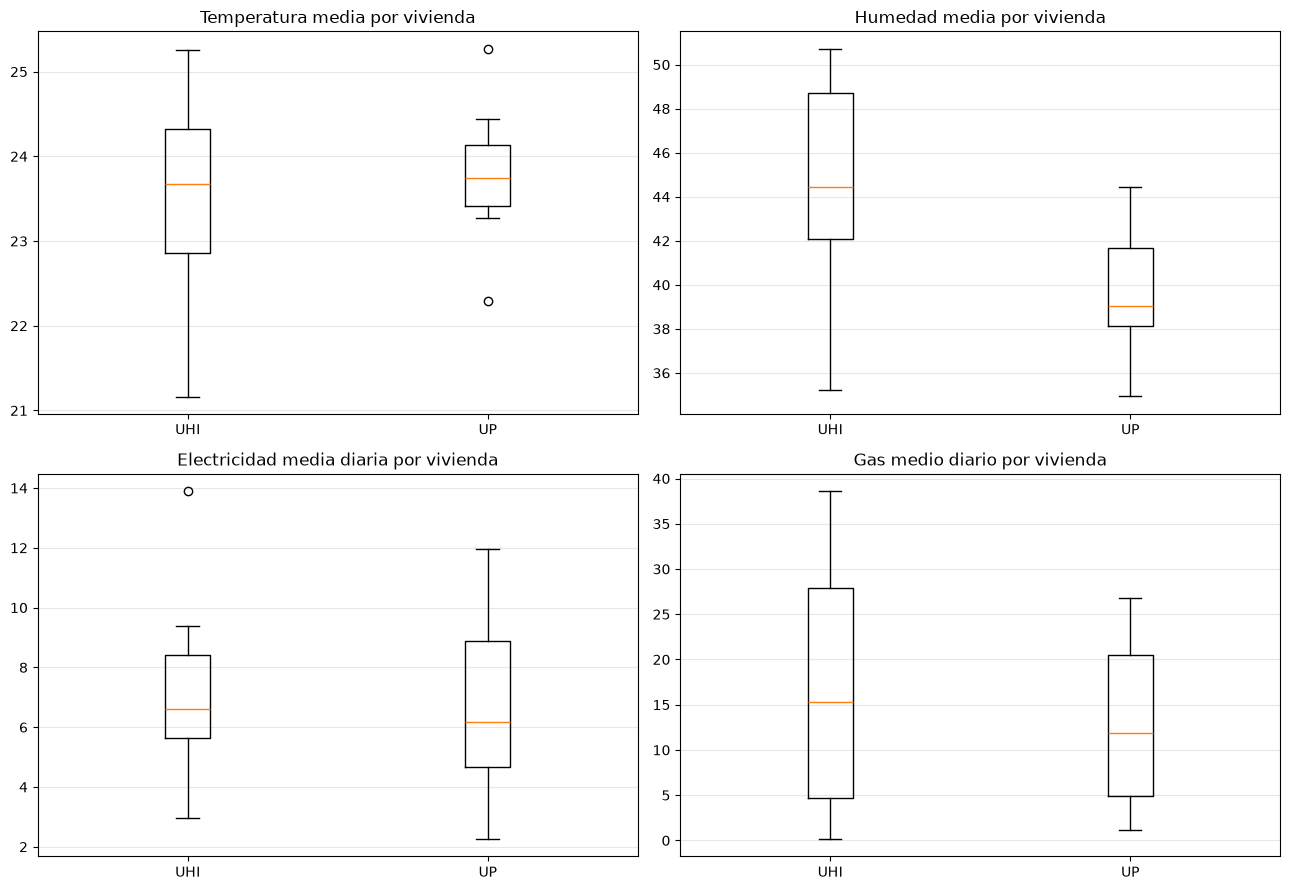

In [82]:
import matplotlib.pyplot as plt

variables = [
    "TEMPERATURE",
    "HUMIDITY",
    "ELECTRICITY",
    "GAS"
]

titles = [
    "Temperatura media por vivienda",
    "Humedad media por vivienda",
    "Electricidad media diaria por vivienda",
    "Gas medio diario por vivienda"
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, variable, title in zip(axes.flat, variables, titles):

    data = [
        df_house.loc[df_house["Group"] == group, variable].dropna()
        for group in ["UHI", "UP"]
    ]

    ax.boxplot(data, tick_labels=["UHI", "UP"])
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Conclusión H03 · Las diferencias entre zonas son descriptivas, no causales

La comparación de los indicadores medios por vivienda muestra diferencias
entre ambos grupos principalmente en humedad y consumo de gas.

Las viviendas UHI presentan una humedad media superior a las UP. También
muestran una mediana de consumo diario de gas más elevada, aunque existe
una considerable variabilidad dentro de ambos grupos.

Por otro lado, las temperaturas medias son muy similares y no se aprecian
diferencias claras en el consumo eléctrico diario.

En conjunto, los resultados ofrecen un apoyo descriptivo parcial a H03.
Estas diferencias deben interpretarse con cautela, dado que la muestra
está formada por 20 viviendas y el análisis no permite establecer
relaciones causales.

In [83]:
# Tabla comparativa de indicadores medios por vivienda

df_h04 = df_house.copy()

df_h04 = df_h04.sort_values(
    by="Group"
).round(2)

df_h04

,Group,House,TEMPERATURE,HUMIDITY,ELECTRICITY,GAS
0,UHI,D01,24.36,42.02,9.39,14.81
8,UHI,D15,23.95,35.25,2.95,30.03
7,UHI,D13,24.21,44.68,6.57,0.16
6,UHI,D11,21.79,50.72,NaN,0.39
5,UHI,D09,23.25,44.21,8.43,21.49
9,UHI,D16,25.26,37.32,13.89,38.60
3,UHI,D04,22.73,45.90,5.65,15.38
2,UHI,D03,21.16,50.04,6.62,15.16
1,UHI,D02,24.66,49.66,5.30,1.28
4,UHI,D06,23.41,42.31,8.19,38.13


In [84]:
# Resumen de diferencias entre viviendas

df_h04[["TEMPERATURE", "HUMIDITY", "ELECTRICITY", "GAS"]].agg(
    ["min", "max", "mean", "std"]
).round(2)

,TEMPERATURE,HUMIDITY,ELECTRICITY,GAS
min,21.16,34.93,2.26,0.16
max,25.27,50.72,13.89,38.60
mean,23.63,41.95,7.18,15.15
std,1.05,4.80,3.11,12.03


### Conclusión H04 · El consumo de gas varía mucho entre hogares

Se comparan los valores medios de temperatura, humedad y consumo
energético de cada vivienda para identificar diferencias individuales
que pueden quedar ocultas al analizar únicamente los grupos UHI y UP.

El análisis es descriptivo y utiliza la vivienda como unidad de
comparación.

# 7. Conclusión general · No existe un único patrón de consumo válido para todas las viviendas

El análisis exploratorio de los datos de monitorización energética
residencial ha permitido identificar patrones y diferencias en las
condiciones ambientales interiores y los consumos energéticos de
20 viviendas pertenecientes a los grupos UHI y UP.

### Principales conclusiones

1. **Temperatura y consumo energético:** se observa una asociación
negativa entre temperatura interior y consumo de gas, más marcada
que la relación observada con la electricidad.

2. **Humedad y consumo energético:** la humedad presenta asociaciones
positivas con los consumos de electricidad y gas, aunque su intensidad
varía entre viviendas.

3. **Comparación UHI y UP:** las viviendas UHI presentan mayor humedad
media y una mediana de consumo de gas superior. No se observan
diferencias relevantes en temperatura ni electricidad.

4. **Variabilidad entre viviendas:** los hogares muestran diferencias
individuales importantes en sus consumos energéticos, especialmente
en el gas.

### Interpretación global

Los resultados muestran que las condiciones ambientales interiores
y los consumos energéticos presentan patrones de asociación y una
variabilidad considerable entre viviendas.

El análisis permite identificar tendencias y diferencias descriptivas,
pero no establecer relaciones causales. Las asociaciones observadas
pueden estar condicionadas por factores que no están disponibles en
el conjunto de datos.

### Limitaciones del estudio

- El análisis incluye únicamente 20 viviendas.
- No se dispone de información sobre temperatura exterior.
- No se conocen todas las características constructivas y de ocupación
  de las viviendas.
- Existen registros ausentes y algunos valores energéticos negativos.
- La cobertura temporal no es idéntica para todas las variables y viviendas.
- La frecuencia de registro es de 15 minutos, pero los análisis comparativos
  entre hogares se han realizado utilizando la vivienda como unidad
  estadística.
- Las asociaciones estadísticas no permiten establecer causalidad.

### Conclusión final

El estudio demuestra la utilidad de los datos de monitorización
residencial para explorar la relación entre las condiciones ambientales
interiores y el comportamiento energético de las viviendas.

Destaca especialmente la relación observada entre temperatura interior
y consumo de gas, así como las diferencias de comportamiento energético
entre hogares.

## H04 · La variabilidad del gas entre viviendas supera a la de electricidad

Se representan por separado electricidad y gas. Cada barra corresponde a la media diaria por vivienda calculada en `df_house`; el color distingue los grupos UHI y UP. Se muestran los valores disponibles, por lo que D11 no aparecerá en electricidad si no tiene registros.

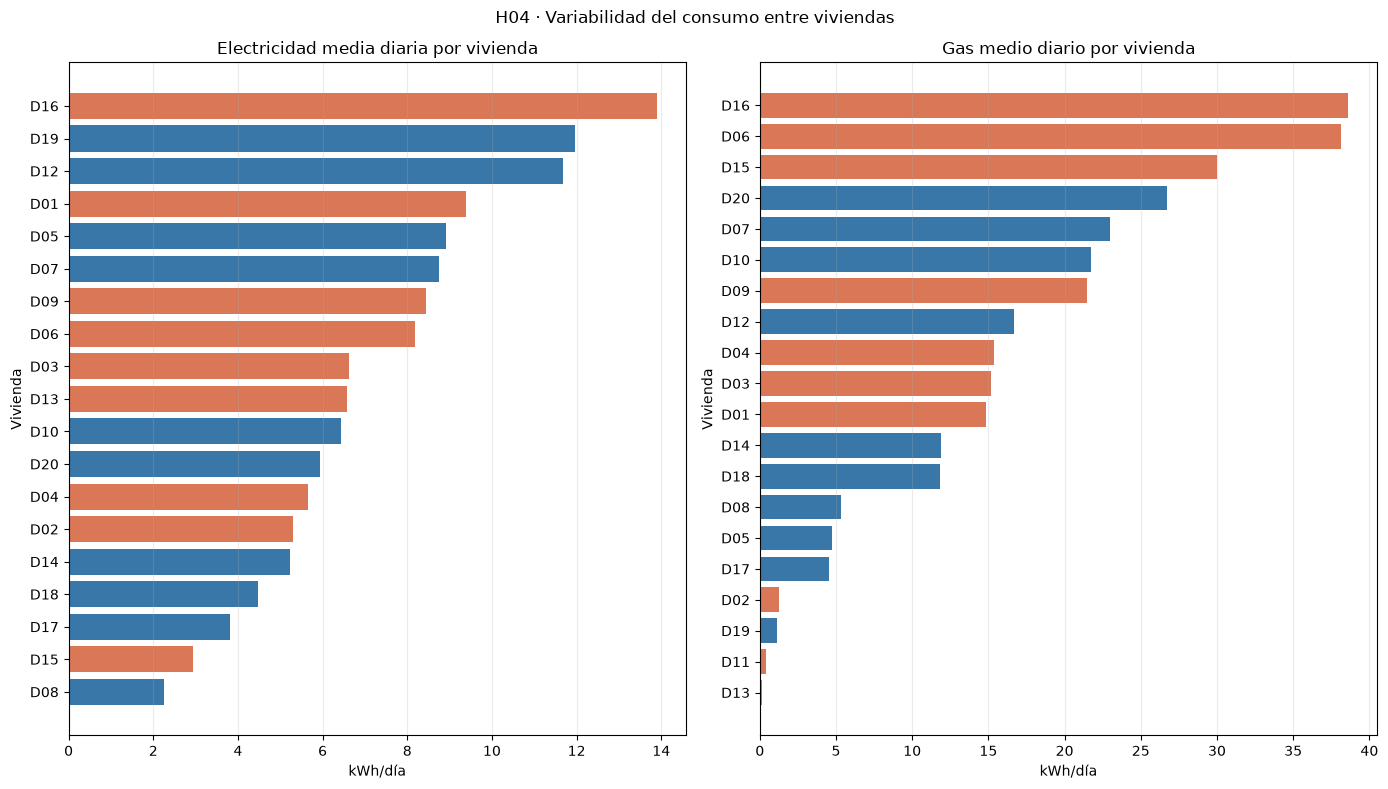

,Group,House,ELECTRICITY,GAS
0,UHI,D01,9.39,14.81
8,UHI,D15,2.95,30.03
7,UHI,D13,6.57,0.16
6,UHI,D11,NaN,0.39
5,UHI,D09,8.43,21.49
9,UHI,D16,13.89,38.60
3,UHI,D04,5.65,15.38
2,UHI,D03,6.62,15.16
1,UHI,D02,5.30,1.28
4,UHI,D06,8.19,38.13


In [85]:
fig, axes = plt.subplots(1, 2, figsize=(14, 8))

titulos_consumo = {
    "ELECTRICITY": "Electricidad media diaria por vivienda",
    "GAS": "Gas medio diario por vivienda"
}
unidades_consumo = {
    "ELECTRICITY": "kWh/día",
    "GAS": "kWh/día"
}

for ax, variable in zip(axes, ["ELECTRICITY", "GAS"]):
    datos = df_house[["Group", "House", variable]].dropna().copy()
    datos = datos.sort_values(variable, ascending=True)
    colores = datos["Group"].map(colores_grupo)

    ax.barh(datos["House"], datos[variable], color=colores)
    ax.set_title(titulos_consumo[variable])
    ax.set_xlabel(unidades_consumo[variable])
    ax.grid(axis="x", alpha=0.25)

axes[0].set_ylabel("Vivienda")
axes[1].set_ylabel("Vivienda")
fig.suptitle("H04 · Variabilidad del consumo entre viviendas")
fig.tight_layout()
plt.show()

display(
    df_house[["Group", "House", "ELECTRICITY", "GAS"]]
    .sort_values("Group")
    .round(2)
)

**Interpretación:** las barras permiten identificar la dispersión del consumo medio diario entre hogares y comparar visualmente los dos grupos. Las diferencias entre viviendas no explican por sí mismas sus causas. Además, las medias diarias pueden verse afectadas por la cobertura desigual de registros.